# Анализ данных VK Case Champ 2026

Ядро: **Python (VK Case Champ 2026)**. Первые ячейки проверяют подключение и показывают только каталог базы. Измените SQL для своего анализа.

In [1]:
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.family"] = "DejaVu Sans"


In [2]:
# Запускайте Jupyter из корня проекта.
DB_PATH = Path("outputs/vk_commerce.duckdb")
con = duckdb.connect(
    str(DB_PATH), 
    read_only=True
)

In [3]:
def show_table(df):
    formats = {
        col: (
            lambda value: f"{value:,.3f}".rstrip("0").rstrip(".")
            .replace(",", " ")
            .replace(".", ",")
        )
        for col in df.select_dtypes(include="number").columns
    }
    display(df.style.format(formats, na_rep="—").hide(axis="index"))


totals = con.sql("SELECT * FROM raw.market_totals").df()

period = totals.loc[totals["Метрика"].eq("Период")].iloc[0]
print(
    f"Период: {period['Период с']:%d.%m.%Y}"
    f" — {period['Период по']:%d.%m.%Y}"
)

Период: 01.09.2026 — 30.09.2026


## Воронки продаж

In [4]:
metrics = [
    "Показы товаров",
    "Открытия карточки товара",
    "Нажатия на кнопку в карточке",
    "Прямые переходы к Партнёру 1 (без открытия карточки)",
    "Оформленные заказы",
    "Оплаченные заказы",
    "GMV, ₽",
    "Средний чек, ₽",
    "Уникальные покупатели за 30 дней",
    "Заказов на покупателя",
    "Доля повторных покупателей (2+ заказа), %",
    "Конверсия: показ → открытие карточки, %",
    "Конверсия: открытие карточки → заказ, %",
    "Конверсия: показ → заказ, %",
]

funnel = totals.set_index("Метрика").loc[
    metrics, ["Маркет Вконтакте", "Партнёр 1"]
].reset_index()

show_table(funnel)

Метрика,Маркет Вконтакте,Партнёр 1
Показы товаров,4 777 750 023,5 729 628 790
Открытия карточки товара,193 512 461,86 882 822
Нажатия на кнопку в карточке,5 969 063,36 626 075
Прямые переходы к Партнёру 1 (без открытия карточки),—,106 914 679
Оформленные заказы,413 740,4 927 525
Оплаченные заказы,4 903,—
"GMV, ₽",1 564 546 740,5 119 514 685
"Средний чек, ₽",3 781,1 039
Уникальные покупатели за 30 дней,296 148,2 901 334
Заказов на покупателя,"1,4","1,7"


**VK лучше привлекает внимание к карточкам, но реже доводит его до действия и заказа.**

| Показатель | Маркет VK | Партнёр |
|---|---:|---:|
| Открытия / показы | **4,05%** | 1,52% |
| Нажатия / открытия | 3,08% | **42,16%** |
| Заказы / показы | 0,0087% | **0,0860%** |
| GMV на 1 000 показов | 327 ₽ | **894 ₽** |
| Средний чек | **3 781 ₽** | 1 039 ₽ |
| Доля повторных покупателей | 19,0% | **26,6%** |

**Ключевые выводы:**

- Приоритет исследования — **переход от карточки к действию**: отношение нажатий к открытиям у VK ниже в **13,7 раза**.
- Партнёр получает в **9,9 раза больше заказов на показ**. Более высокий чек VK сокращает разрыв по GMV на показ до **2,7 раза**.
- Ограничение: у партнёра **106,9 млн прямых переходов**, обходящих карточку. Все его заказы нельзя приписывать открытиям карточек.

## Общая аудитория, контент и поиск

In [5]:
audience = totals.loc[
    totals["Всего"].notna(),
    ["Метрика", "Всего"],
]

show_table(audience)

Метрика,Всего
DAU Маркета Вконтакте (среднее за день),127 406
MAU Маркета Вконтакте (уникальные за 30 дней),2 997 341
"Пользователи, видевшие товары за 30 дней",66 617 967
"Пользователи, открывавшие карточку товара за 30 дней",27 333 960
Открытия карточки товара из постов и клипов,86 321 893
в т.ч. из реферальных постов и клипов,82 324 081
Запросы в товарном поиске,28 585 243
"Доля поисковых запросов с открытием карточки, %","18,4"


## Источники открытий карточек

In [6]:
sources = con.sql('''
    SELECT * 
    FROM raw.market_sources
''').df()

show_table(sources)

Источник,Маркет Вконтакте,"Доля, %: Маркет Вконтакте",Партнёр 1,"Доля, %: Партнёр 1"
Другое,77 753 037,"40,2",5 380 616,"6,2"
Витрина магазина,75 604 323,"39,1",714 540,"0,8"
Лента,18 795 696,"9,7",15 622 386,18
Клипы,17 239 066,"8,9",64 917 109,"74,7"
Поиск,3 707 521,"1,9",159 788,"0,2"
Главная Маркета Вконтакте,412 818,"0,2",88 383,"0,1"
в т.ч. из реферальных постов и клипов,—,—,82 324 081,"94,8"


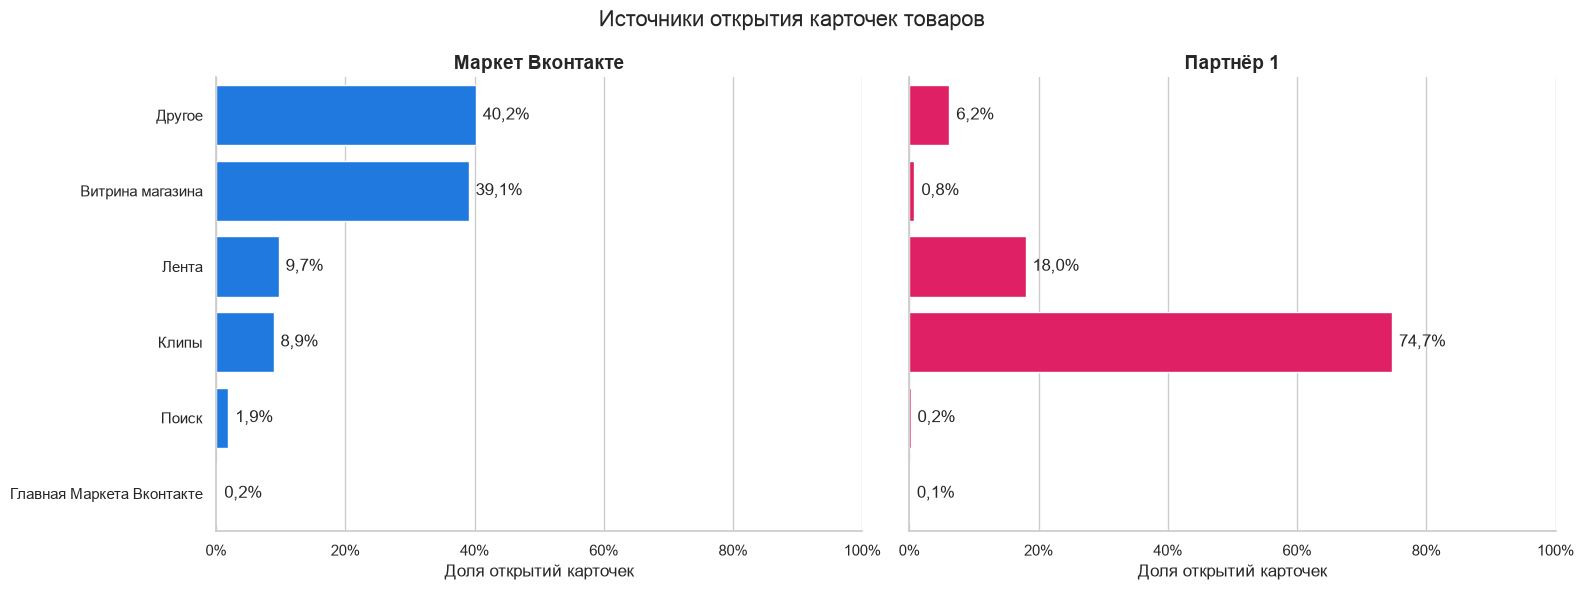

In [7]:
from matplotlib.ticker import PercentFormatter

# «В том числе» пересекается с другими источниками.
plot_data = sources.loc[
    ~sources["Источник"].str.startswith("в т.ч.", na=False)
].copy()

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(
    1, 2, figsize=(16, 6), sharex=True, sharey=True
)

segments = [
    ("Маркет Вконтакте", "Доля, %: Маркет Вконтакте", "#0077FF"),
    ("Партнёр 1", "Доля, %: Партнёр 1", "#FF005C"),
]

for ax, (title, column, color) in zip(axes, segments):
    sns.barplot(
        data=plot_data,
        x=column,
        y="Источник",
        order=plot_data["Источник"].tolist(),
        color=color,
        errorbar=None,
        ax=ax,
    )

    for container in ax.containers:
        labels = [
            f"{bar.get_width():.1f}%".replace(".", ",")
            for bar in container
        ]
        ax.bar_label(container, labels=labels, padding=5)

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Доля открытий карточек")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.grid(axis="y", visible=False)

sns.despine(fig=fig)
fig.suptitle(
    "Источники открытия карточек товаров",
    fontsize=16,
)
plt.tight_layout()
plt.show()

В данном срезе у партнёра основная часть открытий приходится на клипы и ленту,
у VK — на витрину магазина и «Другое». Это структура входов, а не доказательство
эффективности источников по продажам: заказов по источникам в таблице нет.

## Заказы по категориям

In [8]:
categories = con.sql('''
    SELECT
        "Категория",
        "Заказы: Маркет Вконтакте",
        "Заказы: Партнёр 1"
    FROM raw.market_categories
''').df()

category_sum = pd.DataFrame([{
    "Категория": "Сумма строк",
    "Заказы: Маркет Вконтакте": categories["Заказы: Маркет Вконтакте"].sum(),
    "Заказы: Партнёр 1": categories["Заказы: Партнёр 1"].sum(),
}])

show_table(pd.concat([categories, category_sum], ignore_index=True))

Категория,Заказы: Маркет Вконтакте,Заказы: Партнёр 1
Гардероб,29 029,259 808
Хобби и развлечения,110 703,116 999
Другое,41,0
Дом и дача,35 976,1 413 965
Продукты питания,195 355,170 556
Красота и здоровье,13 022,1 240 324
Транспорт,8 254,264 510
Электроника,4 519,30 616
Спорт и отдых,7 781,179 554
Детские товары,10 546,102 803


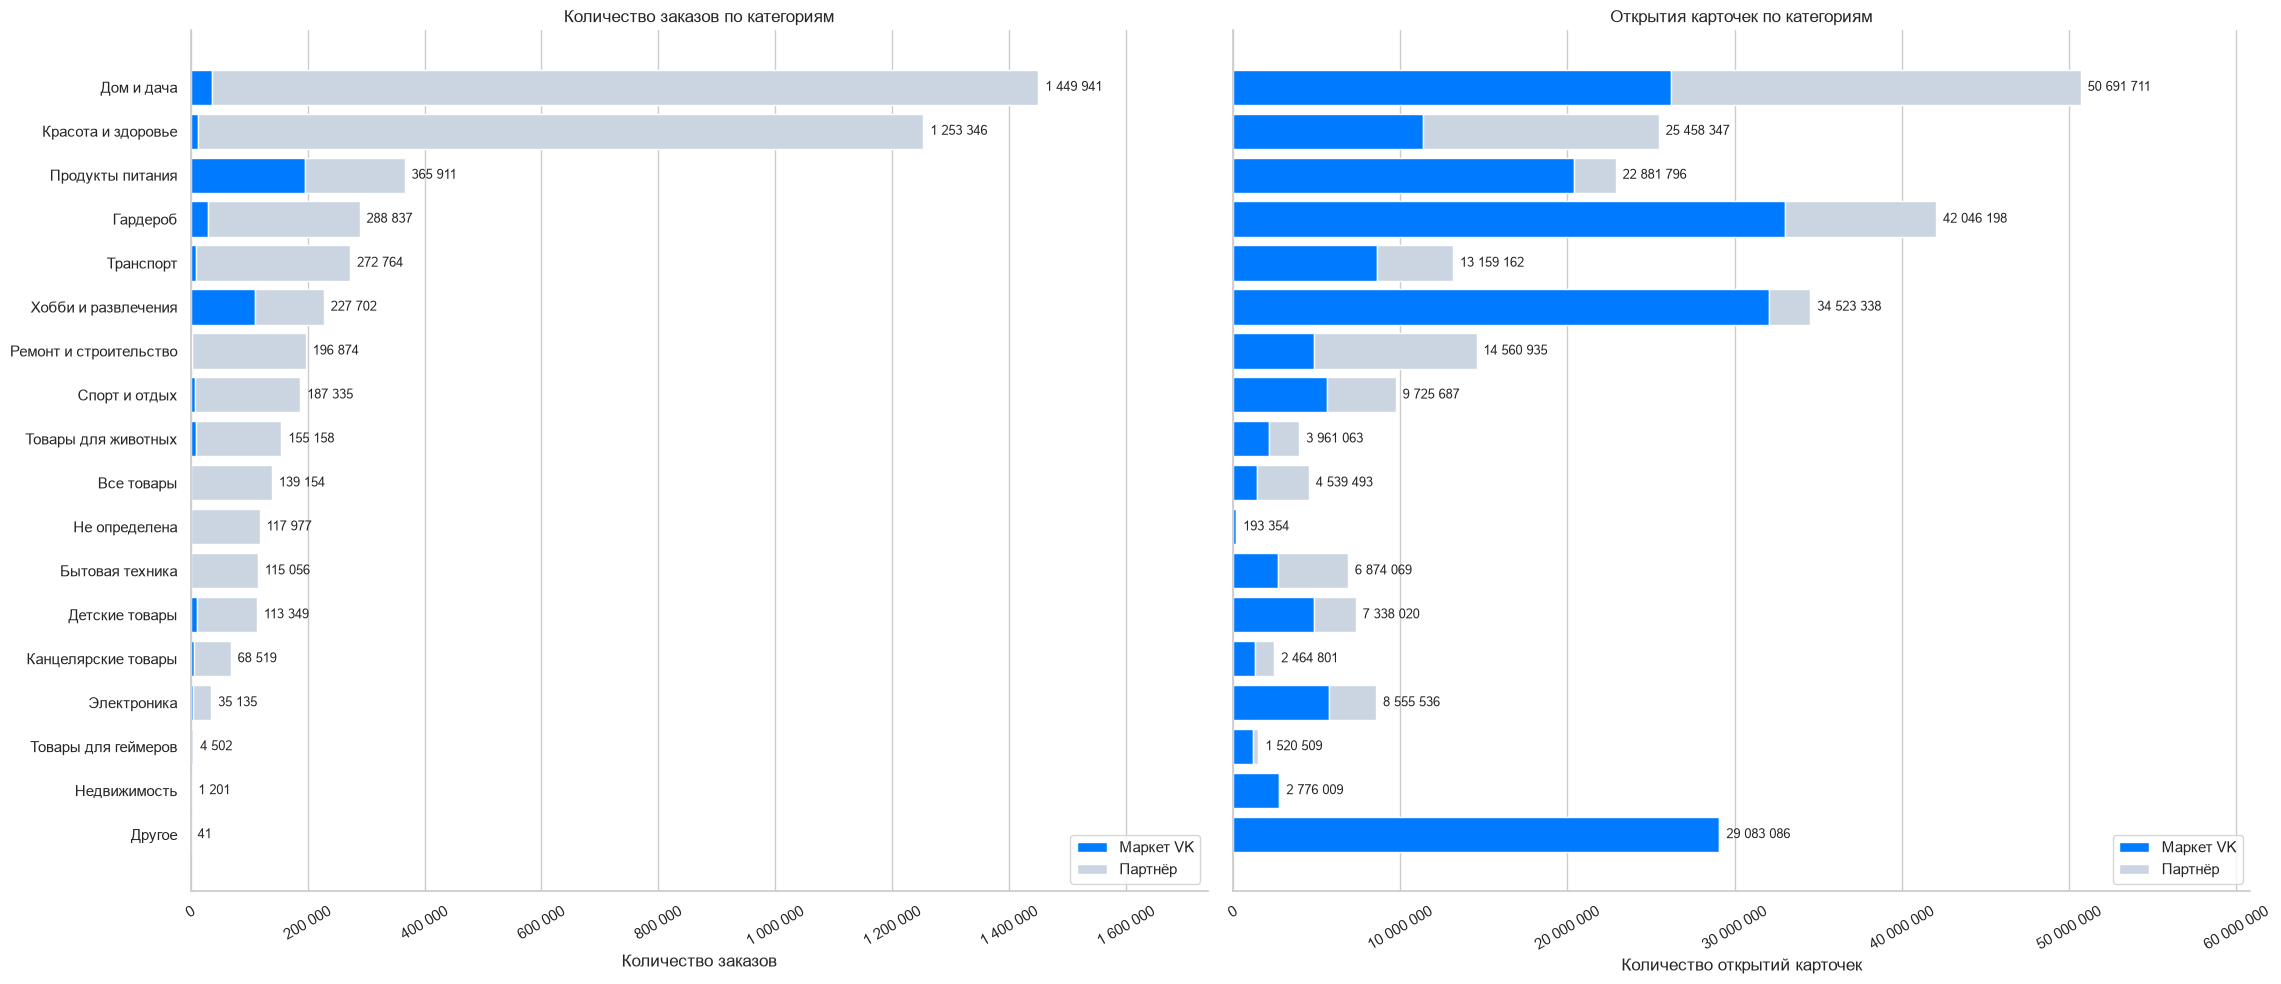

In [9]:
from matplotlib.ticker import FuncFormatter

# Добавляем открытия карточек в исходную таблицу.
categories = con.sql("""
    SELECT
        "Категория",
        "Заказы: Маркет Вконтакте",
        "Заказы: Партнёр 1",
        "Открытия карточки: Маркет Вконтакте",
        "Открытия карточки: Партнёр 1"
    FROM raw.market_categories
""").df()

vk_col = "Заказы: Маркет Вконтакте"
partner_col = "Заказы: Партнёр 1"

plot_data = categories.dropna(subset=[vk_col, partner_col]).copy()
plot_data["Всего заказов"] = plot_data[vk_col] + plot_data[partner_col]
plot_data = (
    plot_data.loc[plot_data["Всего заказов"] > 0]
    .sort_values("Всего заказов", ascending=False)
)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(23, 10), sharey=True)

charts = [
    (
        "Заказы: Маркет Вконтакте",
        "Заказы: Партнёр 1",
        "Количество заказов",
        "Количество заказов по категориям",
    ),
    (
        "Открытия карточки: Маркет Вконтакте",
        "Открытия карточки: Партнёр 1",
        "Количество открытий карточек",
        "Открытия карточек по категориям",
    ),
]

for ax, (vk_col, partner_col, xlabel, title) in zip(axes, charts):
    ax.barh(
        plot_data["Категория"],
        plot_data[vk_col],
        color="#007BFF",
        label="Маркет VK",
    )

    partner_bars = ax.barh(
        plot_data["Категория"],
        plot_data[partner_col],
        left=plot_data[vk_col],
        color="#CBD5E1",
        label="Партнёр",
    )

    totals = plot_data[vk_col] + plot_data[partner_col]
    ax.bar_label(
        partner_bars,
        labels=[
            f"{int(value):,}".replace(",", " ")
            if pd.notna(value) else ""
            for value in totals
        ],
        padding=5,
        fontsize=9,
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.set_title(title)
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda value, _: f"{value:,.0f}".replace(",", " "))
    )
    ax.tick_params(axis="x", labelrotation=30)
    ax.margins(x=0.20)
    ax.set_axisbelow(True)
    ax.grid(axis="y", visible=False)
    ax.legend()

    sns.despine(ax=ax)

axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

В большинстве категорий число заказов партнёра выше числа заказов VK, при этом доля открытий карточек выше по каждой из категорий, что подтверждает основной сценарий — просмотр в вк и заказ через партнёра.

### Структура открытий и заказов внутри VK

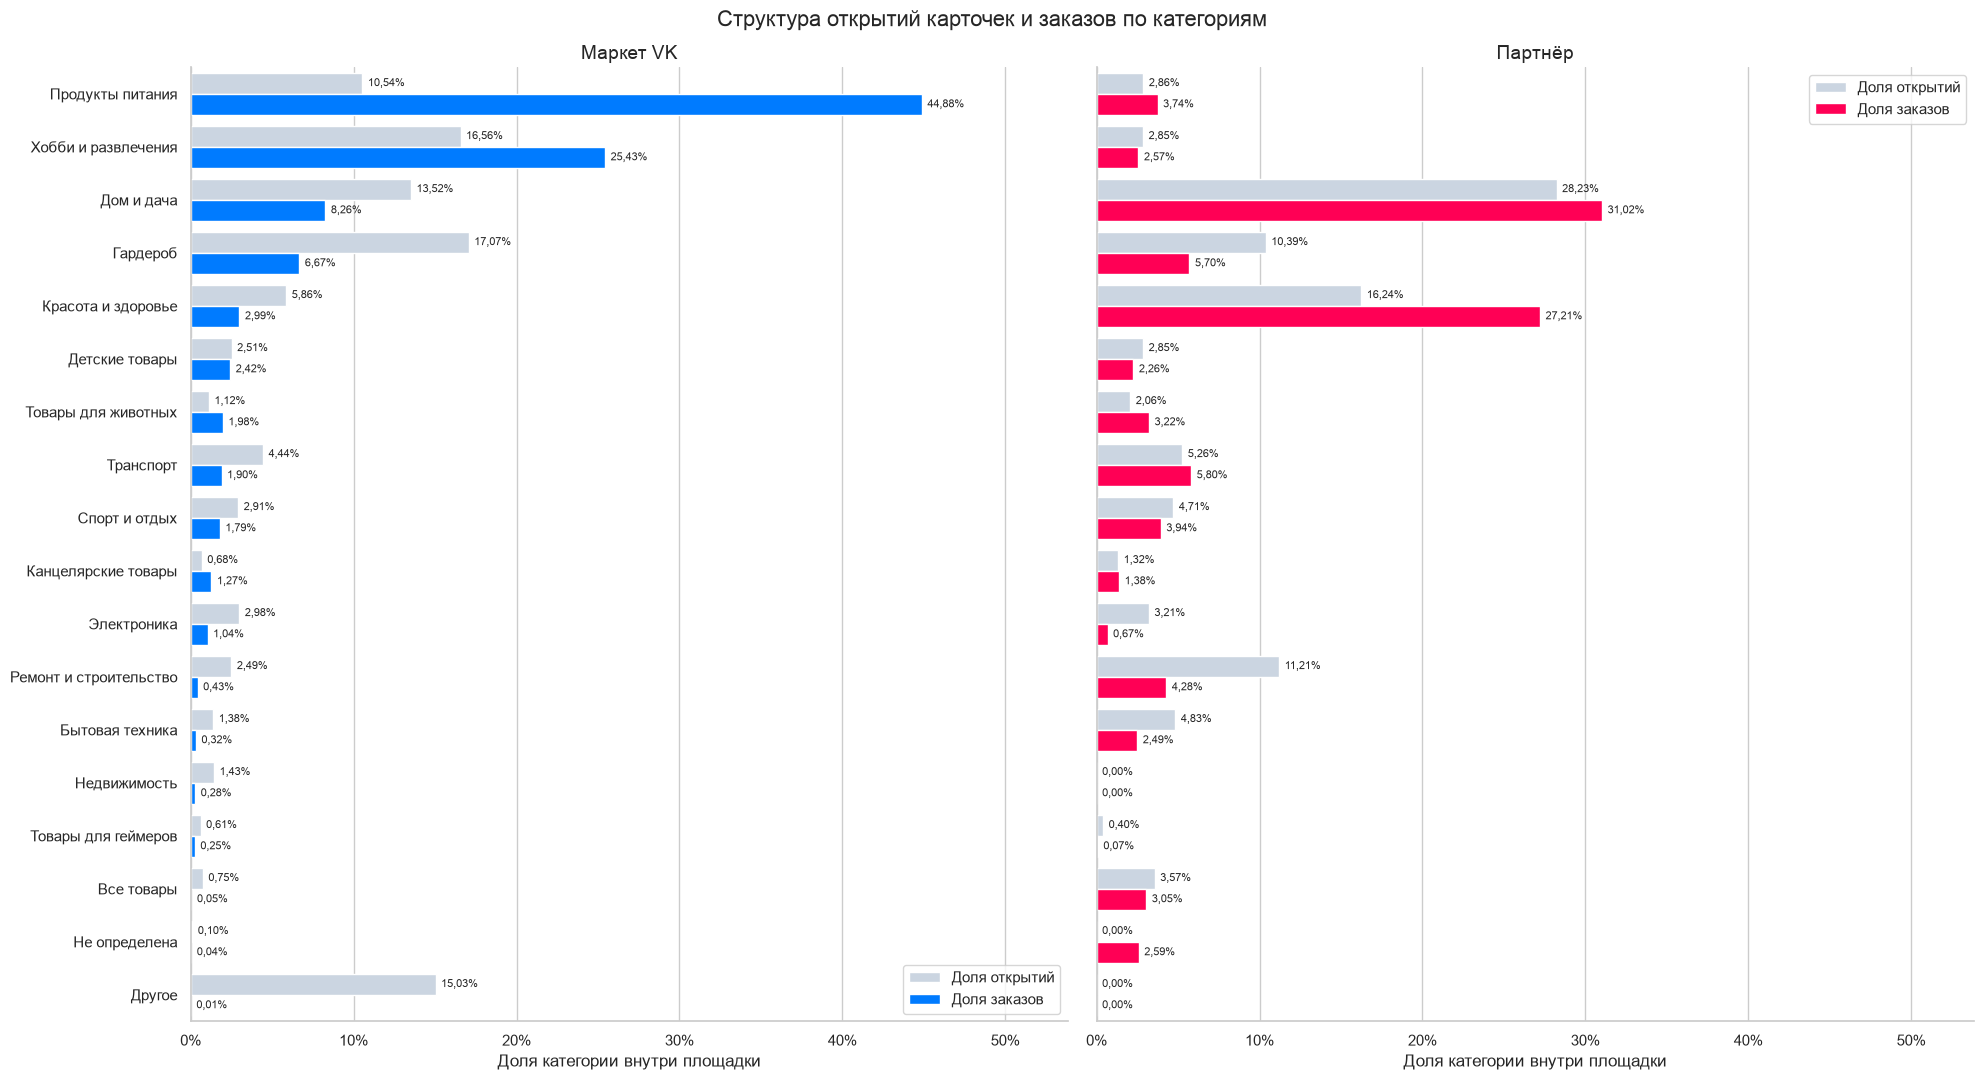

In [10]:
category_structure = con.sql("""
    SELECT
        "Категория",
        "Открытия карточки: Маркет Вконтакте" AS vk_opens,
        "Заказы: Маркет Вконтакте" AS vk_orders,
        "Открытия карточки: Партнёр 1" AS partner_opens,
        "Заказы: Партнёр 1" AS partner_orders
    FROM raw.market_categories
""").df()

# Общий порядок — по числу заказов VK, по убыванию.
order = (
    category_structure
    .sort_values("vk_orders", ascending=False)["Категория"]
    .tolist()
)

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(
    1, 2, figsize=(20, 11), sharex=True, sharey=True
)

segments = [
    ("Маркет VK", "vk_opens", "vk_orders", "#007BFF"),
    ("Партнёр", "partner_opens", "partner_orders", "#FF0055"),
]

max_share = 0

for ax, (title, opens_col, orders_col, color) in zip(axes, segments):
    segment = category_structure[["Категория"]].copy()

    segment["Доля открытий"] = (
        100 * category_structure[opens_col]
        / category_structure[opens_col].sum()
    )
    segment["Доля заказов"] = (
        100 * category_structure[orders_col]
        / category_structure[orders_col].sum()
    )

    max_share = max(
        max_share,
        segment[["Доля открытий", "Доля заказов"]].max().max(),
    )

    plot_data = segment.melt(
        id_vars="Категория",
        value_vars=["Доля открытий", "Доля заказов"],
        var_name="Показатель",
        value_name="Доля",
    )

    sns.barplot(
        data=plot_data,
        y="Категория",
        x="Доля",
        hue="Показатель",
        order=order,
        hue_order=["Доля открытий", "Доля заказов"],
        palette={
            "Доля открытий": "#CBD5E1",
            "Доля заказов": color,
        },
        saturation=1,
        errorbar=None,
        ax=ax,
    )

    for container in ax.containers:
        ax.bar_label(
            container,
            labels=[
                f"{bar.get_width():.2f}%".replace(".", ",")
                for bar in container
            ],
            padding=4,
            fontsize=8,
        )

    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Доля категории внутри площадки")
    ax.set_ylabel("")
    ax.xaxis.set_major_formatter(
        PercentFormatter(xmax=100, decimals=0)
    )
    ax.set_axisbelow(True)
    ax.grid(axis="y", visible=False)
    ax.legend(title="")

axes[0].set_xlim(0, max_share * 1.2)

fig.suptitle(
    "Структура открытий карточек и заказов по категориям",
    fontsize=16,
)
sns.despine(fig=fig)
plt.tight_layout()
plt.show()

- Ядро продаж VK — еда и хобби: 70,3% заказов при 27,1% открытий карточек. Нужно проверить, сколько продавцов обеспечивают результат.
- Ядро партнёра — дом и красота: вместе 58,2% заказов.
- Гардероб часто смотрят, но доля заказов заметно ниже у обеих площадок. Причина может быть связана с категорией и сценарием покупки, а не только с интерфейсом VK.

! Есть аномалии классификации: "Другое" у VK — 15% открытий почти без заказов, а "Не определена" у партнёра — 2,6% заказов без открытий.

### Масштаб интереса x интенсивность заказов

X — доля категории во всех открытиях площадки: насколько велик интерес к категории.

Y — индекс интенсивности заказов: отношение доли заказов к доле открытий.
$$
\text{Индекс} =
\frac{\text{Доля категории в заказах}}
{\text{Доля категории в открытиях}}
$$
1 — средняя интенсивность для площадки; 2 — заказов на открытие вдвое больше среднего. Размер точки — доля категории в заказах.

Знаменатели здесь рассчитаны **без** «Другое», «Все товары» и «Не определена»;
категории без открытий также не входят в расчёт. Это среднее среди оставшихся
категорий. На предыдущем графике структуры знаменатели включают все категории.
Индекс — отношение агрегированных событий, не пользовательская конверсия.
Шкалы осей независимы; индексы нормированы на собственное среднее площадки.

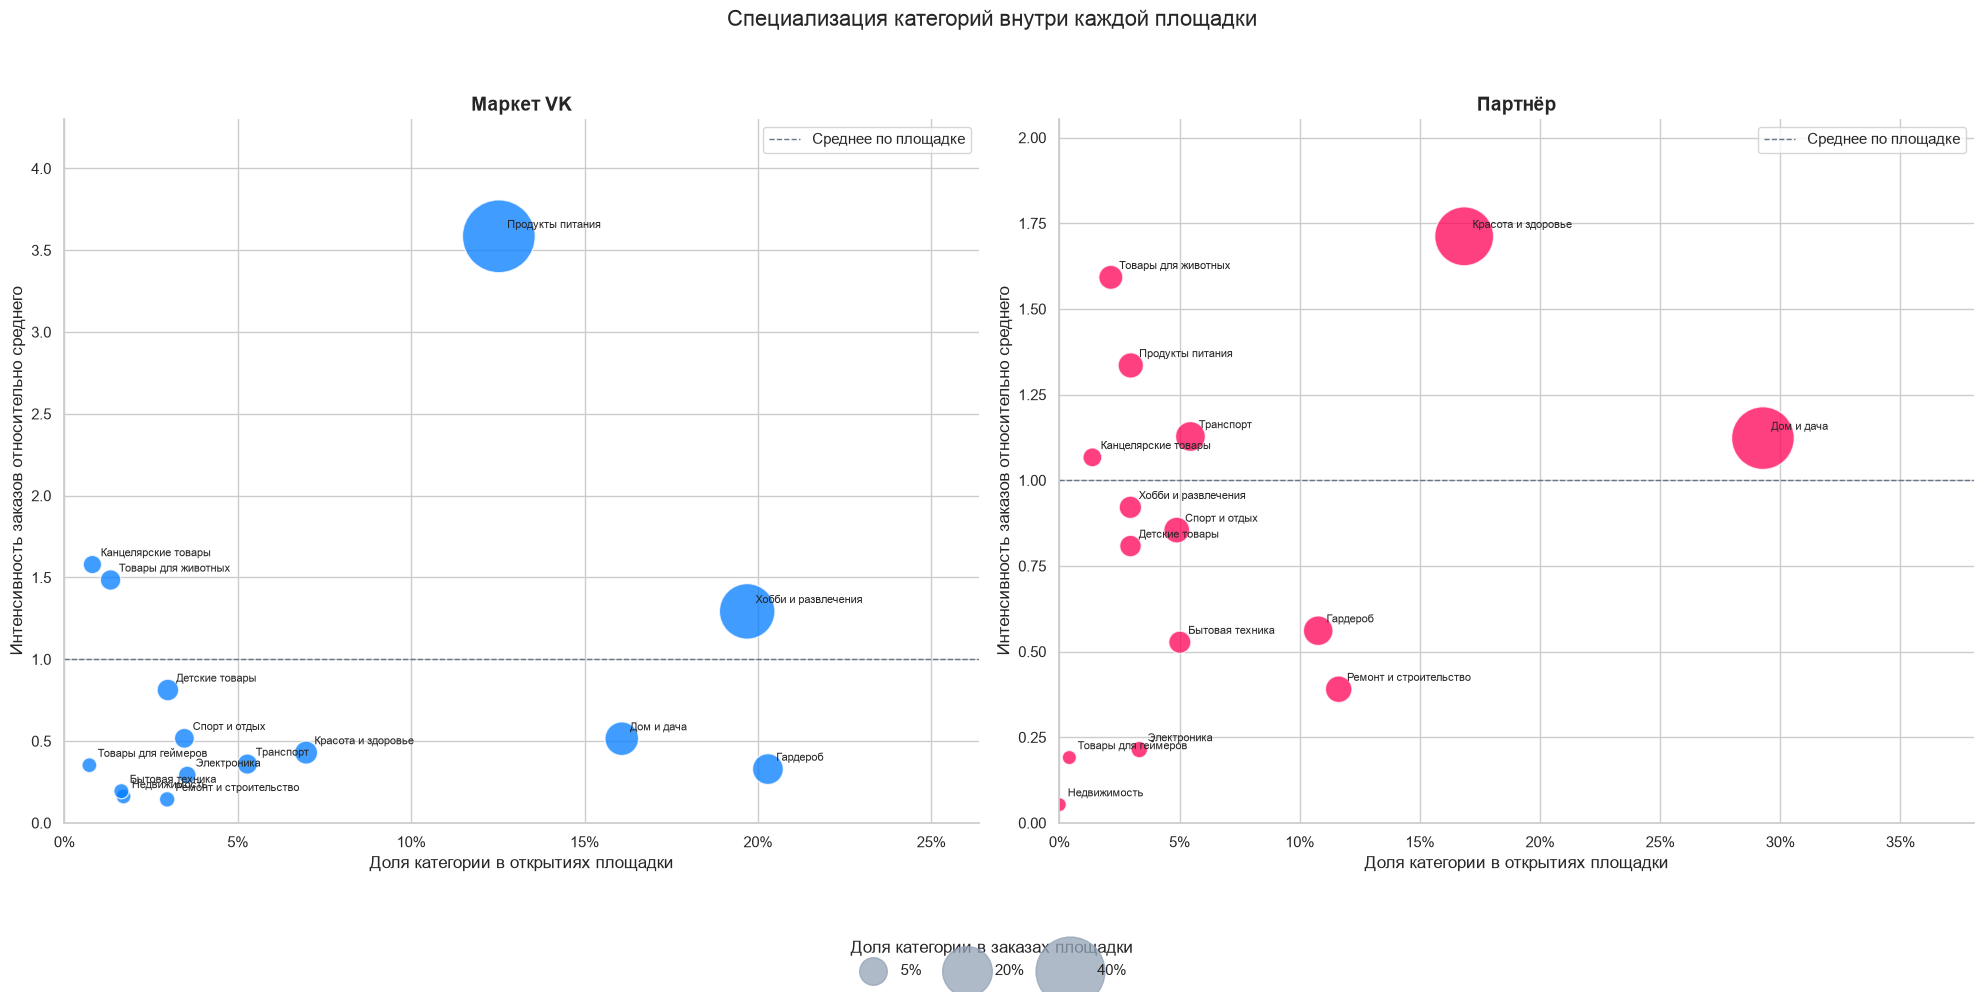

In [11]:
category_map = con.sql("""
    SELECT
        "Категория",
        "Открытия карточки: Маркет Вконтакте" AS vk_opens,
        "Заказы: Маркет Вконтакте" AS vk_orders,
        "Открытия карточки: Партнёр 1" AS partner_opens,
        "Заказы: Партнёр 1" AS partner_orders
    FROM raw.market_categories
""").df()

segments = [
    ("Маркет VK", "vk_opens", "vk_orders", "#007BFF"),
    ("Партнёр", "partner_opens", "partner_orders", "#FF0055"),
]

service_categories = ["Другое", "Все товары", "Не определена"]
frames = []

for title, opens_col, orders_col, color in segments:
    frame = category_map[
        ["Категория", opens_col, orders_col]
    ].rename(columns={
        opens_col: "Открытия",
        orders_col: "Заказы",
    })

    frame = frame.loc[
        ~frame["Категория"].isin(service_categories)
    ].dropna(subset=["Открытия", "Заказы"])

    frame = frame.loc[frame["Открытия"] > 0].copy()
    frame["Площадка"] = title

    # Доли считаются среди оставшихся содержательных категорий.
    frame["Доля открытий"] = (
        100 * frame["Открытия"] / frame["Открытия"].sum()
    )
    frame["Доля заказов"] = (
        100 * frame["Заказы"] / frame["Заказы"].sum()
    )
    frame["Индекс интенсивности"] = (
        frame["Доля заказов"] / frame["Доля открытий"]
    )

    frames.append(frame)

relative_map = pd.concat(frames, ignore_index=True)

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(
    1, 2,
    figsize=(20, 10),
    sharex=False,
    sharey=False,
)

for ax, (title, _, _, color) in zip(axes, segments):
    frame = relative_map.loc[
        relative_map["Площадка"].eq(title)
    ]

    sns.scatterplot(
        data=frame,
        x="Доля открытий",
        y="Индекс интенсивности",
        size="Доля заказов",
        size_norm=(0, 100),
        sizes=(100, 6000),
        color=color,
        alpha=0.75,
        edgecolor="white",
        linewidth=1,
        legend=False,
        ax=ax,
    )

    for _, row in frame.iterrows():
        ax.annotate(
            row["Категория"],
            xy=(
                row["Доля открытий"],
                row["Индекс интенсивности"],
            ),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=8,
        )

    ax.axhline(
        1,
        color="#64748B",
        linestyle="--",
        linewidth=1,
        label="Среднее по площадке",
    )

    ax.set_xlim(0, frame["Доля открытий"].max() * 1.3)
    ax.set_ylim(0, frame["Индекс интенсивности"].max() * 1.2)

    ax.xaxis.set_major_formatter(
        PercentFormatter(xmax=100, decimals=0)
    )

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Доля категории в открытиях площадки")
    ax.set_ylabel("Интенсивность заказов относительно среднего")
    ax.set_axisbelow(True)
    ax.legend(loc="upper right")

legend_shares = [5, 20, 40]
handles = [
    axes[1].scatter(
        [], [],
        s=100 + (6000 - 100) * share / 100,
        color="#94A3B8",
        alpha=0.75,
        label=f"{share}%",
    )
    for share in legend_shares
]

fig.legend(
    handles=handles,
    title="Доля категории в заказах площадки",
    loc="lower center",
    ncol=3,
    frameon=False,
)

fig.suptitle(
    "Специализация категорий внутри каждой площадки",
    fontsize=16,
)

sns.despine(fig=fig)
plt.tight_layout(rect=[0, 0.1, 1, 0.95])
plt.show()

### Относительная специализация ВК

$$
\text{Индекс специализации} =
\frac{\text{Заказы VK в категории / Все заказы VK}}
{\text{Заказы партнёра в категории / Все заказы партнёра}}
$$
Значение выше 1 означает, что категория сильнее представлена в структуре VK.

Здесь знаменатели включают **все** категории листа; служебные категории только
скрыты на графике. Это отличается от нормировки пузырьковой диаграммы.
Устойчивость результатов к выбору знаменателя проверяется ниже.

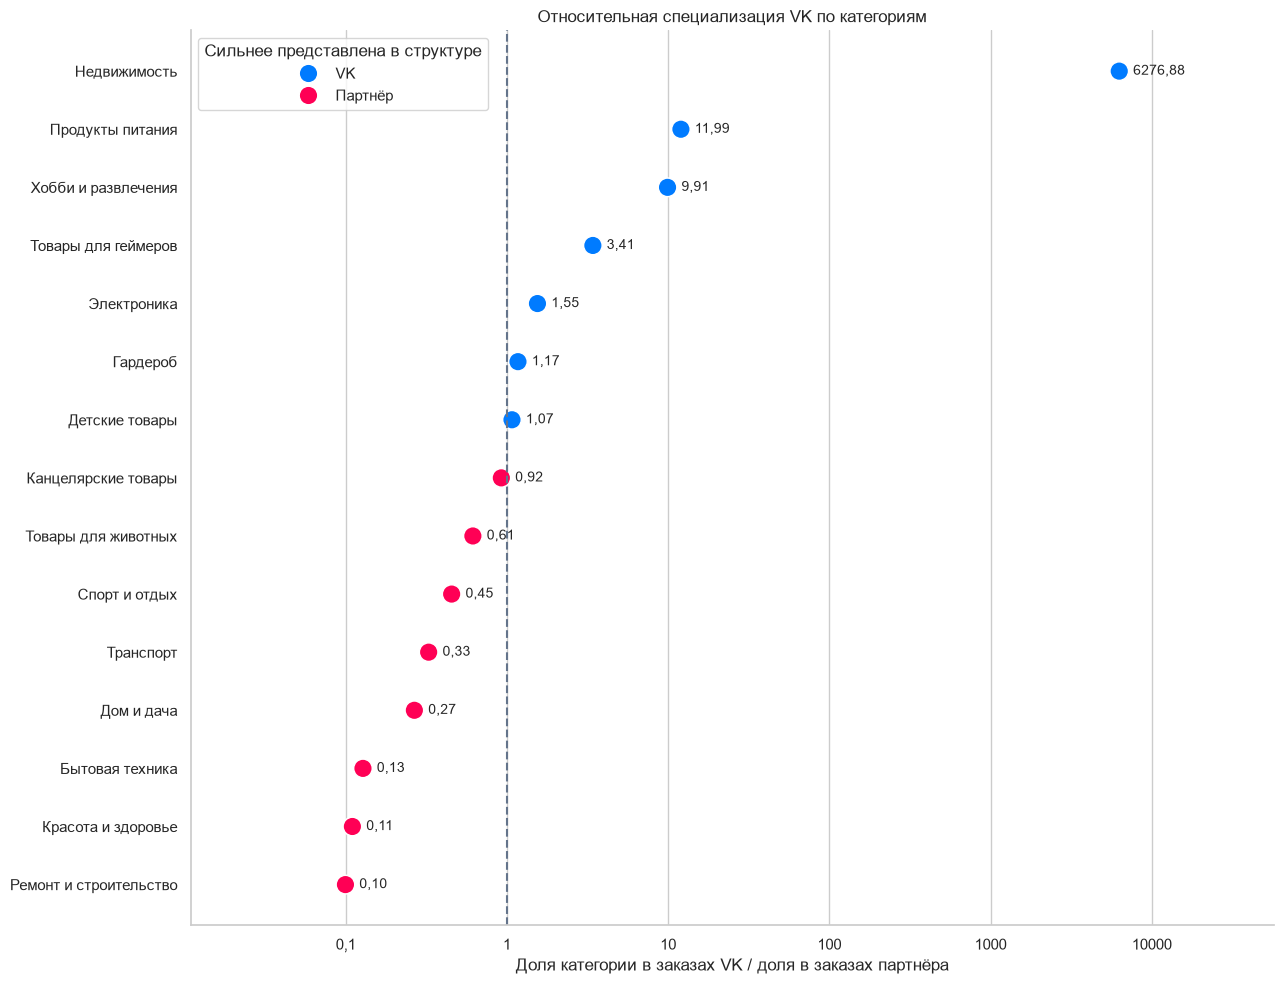

In [12]:
vk_col = "Заказы: Маркет Вконтакте"
partner_col = "Заказы: Партнёр 1"

specialization = categories.copy()

# Знаменатели — все заказы соответствующей площадки на листе категорий.
specialization["Доля заказов VK"] = (
    specialization[vk_col] / specialization[vk_col].sum()
)
specialization["Доля заказов партнёра"] = (
    specialization[partner_col] / specialization[partner_col].sum()
)

# При нуле заказов партнёра конечный индекс не определён.
specialization["Индекс специализации"] = (
    specialization["Доля заказов VK"]
    / specialization["Доля заказов партнёра"].replace(0, float("nan"))
)

# Служебные категории скрываем только на графике.
plot_data = specialization.loc[
    ~specialization["Категория"].isin(
        ["Другое", "Все товары", "Не определена"]
    )
    & specialization["Индекс специализации"].gt(0)
].sort_values("Индекс специализации", ascending=False).copy()

plot_data["Специализация"] = plot_data["Индекс специализации"].map(
    lambda value: "VK" if value >= 1 else "Партнёр"
)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(13, 10))

sns.scatterplot(
    data=plot_data,
    x="Индекс специализации",
    y="Категория",
    hue="Специализация",
    hue_order=["VK", "Партнёр"],
    palette={"VK": "#007BFF", "Партнёр": "#FF0055"},
    s=180,
    ax=ax,
)

for _, row in plot_data.iterrows():
    ax.annotate(
        f"{row['Индекс специализации']:.2f}".replace(".", ","),
        xy=(row["Индекс специализации"], row["Категория"]),
        xytext=(10, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
    )

ax.axvline(1, color="#64748B", linestyle="--", linewidth=1.5)

# Логарифмическая шкала позволяет показать очень разные индексы.
ax.set_xscale("log")
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:g}".replace(".", ","))
)
ax.margins(x=0.2)
ax.set_title("Относительная специализация VK по категориям")
ax.set_xlabel("Доля категории в заказах VK / доля в заказах партнёра")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)
ax.legend(title="Сильнее представлена в структуре")

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

- Еда и хобби — основная специализация VK: их доли в структуре заказов примерно в 12 и 10 раз выше, чем у партнёра. Обе категории имеют интенсивность заказов выше среднего внутри VK.
- У партнёра выделяются дом и красота: большой масштаб интереса сочетается с интенсивностью заказов выше его среднего.
- Гардероб и дом у VK привлекают много открытий, но интенсивность заказов ниже среднего. Это приоритетные категории для диагностики пути покупки.
- Зоотовары и канцелярия — небольшие перспективные ниши VK: интенсивность выше среднего, хотя относительно партнёра они не являются специализацией VK.
- Геймерские товары сильнее представлены у VK, но интенсивность ниже среднего. Относительная специализация сама по себе не означает высокую результативность.
- Недвижимость — выброс: огромный индекс объясняется всего двумя заказами партнёра; выбирать её приоритетом на этом основании нельзя.

## Покрытие сводок покупателями

In [13]:
coverage = con.sql('''
    SELECT
        'Покупатели в демографической сводке' AS "Метрика",
        SUM("Покупатели: Маркет Вконтакте") AS "Маркет Вконтакте",
        SUM("Покупатели: Партнёр 1") AS "Партнёр 1"
    FROM raw.buyers

    UNION ALL

    SELECT
        'Покупатели в региональной сводке',
        SUM("Покупатели: Маркет Вконтакте"),
        SUM("Покупатели: Партнёр 1")
    FROM raw.buyers_by_region

    UNION ALL

    SELECT
        'Заказы в демографической сводке',
        SUM("Заказы: Маркет Вконтакте"),
        SUM("Заказы: Партнёр 1")
    FROM raw.buyers

    UNION ALL

    SELECT
        'Заказы в региональной сводке',
        SUM("Заказы: Маркет Вконтакте"),
        SUM("Заказы: Партнёр 1")
    FROM raw.buyers_by_region
''').df()

show_table(coverage)

Метрика,Маркет Вконтакте,Партнёр 1
Покупатели в демографической сводке,295 850,2 901 162
Покупатели в региональной сводке,295 850,2 901 162
Заказы в демографической сводке,413 334,4 557 253
Заказы в региональной сводке,413 334,4 557 253


# Бизнесы

In [15]:
businesses = con.sql("SELECT * FROM raw.businesses").df()

print(f'''
Бизнесов: {len(businesses):,}
Столбцов: {businesses.shape[1]}
Уникальных ID: {businesses['ID бизнеса'].nunique():,}
Полностью повторяющихся строк: {businesses.duplicated().sum()}
''')

display(businesses.head())


Бизнесов: 9,754
Столбцов: 28
Уникальных ID: 9,754
Полностью повторяющихся строк: 0



,ID бизнеса,Тематика,Тип бизнеса (товары / услуги),Число подписчиков,Посты за 30 дней,Клипы за 30 дней,Посты с товаром за 30 дней,Клипы с товаром за 30 дней,Просмотры обычного контента,Лайки обычного контента,...,Подключена доставка,Подключена оплата,Автор оригинального контента (оценка модели),Участие в реферальной программе,Заказы через чекаут,"GMV через чекаут, ₽","Средний чек, ₽","Траты на рекламу всего, ₽",Число активных услуг,"Медианная цена товара, ₽"
0,9308,Мода и стиль,без каталога,2800,66,1,22,1,1000000,51694,...,False,False,True,True,0,0.0,NaN,0.0,0,NaN
1,3078,Спорт,без каталога,98000,7,46,0,7,550000,16429,...,False,False,True,True,0,0.0,NaN,0.0,0,NaN
2,5330,Образование,товарное,12000,380,0,26,0,380000,2530,...,True,True,True,True,83,17150.0,208.0,0.0,0,169.0
3,5072,Развлечения и хобби,товарное,5200,12,0,20,0,260000,319,...,True,True,False,False,2,6250.0,2648.0,0.0,0,1325.0
4,6398,Личный блог,без каталога,440,35,20,7,12,530000,1915,...,False,False,True,True,0,0.0,NaN,0.0,0,NaN


## Качество данных

In [16]:
column_profile = pd.DataFrame({
    "Тип данных": businesses.dtypes.astype(str),
    "Пропуски": businesses.isna().sum(),
    "Пропуски, %": businesses.isna().mean() * 100,
    "Уникальных значений": businesses.nunique(),
})

display(
    column_profile
    .rename_axis("Поле")
    .reset_index()
    .round(2)
)

id_quality = pd.Series({
    "Пропущенные ID": businesses["ID бизнеса"].isna().sum(),
    "Строки с повторяющимися ID": (
        businesses["ID бизнеса"].duplicated(keep=False).sum()
    ),
})

display(id_quality.to_frame("Количество"))

numeric_columns = businesses.select_dtypes(include="number").columns

numeric_quality = pd.DataFrame({
    "Отрицательных значений": businesses[numeric_columns].lt(0).sum(),
    "Нулей": businesses[numeric_columns].eq(0).sum(),
    "Нулей среди заполненных, %": (
        businesses[numeric_columns].eq(0).sum()
        / businesses[numeric_columns].notna().sum().replace(0, np.nan)
        * 100
    ),
})

display(numeric_quality.round(2))

,Поле,Тип данных,Пропуски,"Пропуски, %",Уникальных значений
0,ID бизнеса,str,0,0.00,9754
1,Тематика,str,0,0.00,42
2,Тип бизнеса (товары / услуги),str,0,0.00,4
3,Число подписчиков,int64,0,0.00,225
4,Посты за 30 дней,int64,0,0.00,240
5,Клипы за 30 дней,int64,0,0.00,71
6,Посты с товаром за 30 дней,int64,0,0.00,36
7,Клипы с товаром за 30 дней,int64,0,0.00,21
8,Просмотры обычного контента,int64,0,0.00,319
9,Лайки обычного контента,int64,0,0.00,968


,Количество
Пропущенные ID,0
Строки с повторяющимися ID,0


,Отрицательных значений,Нулей,"Нулей среди заполненных, %"
Число подписчиков,0,6,0.06
Посты за 30 дней,0,2846,29.18
Клипы за 30 дней,0,6686,68.55
Посты с товаром за 30 дней,0,9496,97.35
Клипы с товаром за 30 дней,0,9631,98.74
Просмотры обычного контента,0,141,1.45
Лайки обычного контента,0,2416,24.77
Репосты обычного контента,0,4970,50.95
Просмотры товарного контента,0,8438,86.51
Лайки товарного контента,0,9269,95.03


## Распределения числовых показателей

In [19]:
numeric_description = pd.concat(
    [
        businesses[numeric_columns]
        .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
        .T
        .rename(columns={
            "count": "Заполнено",
            "mean": "Среднее",
            "std": "Станд. отклонение",
            "min": "Минимум",
            "25%": "P25",
            "50%": "Медиана",
            "75%": "P75",
            "90%": "P90",
            "95%": "P95",
            "99%": "P99",
            "max": "Максимум",
        }),
        businesses[numeric_columns]
        .mode()
        .reindex([0])
        .T
        .rename(columns={0: "Мода"}),
    ],
    axis=1,
)

display(numeric_description.round(2))

,Заполнено,Среднее,Станд. отклонение,Минимум,P25,Медиана,P75,P90,P95,P99,Максимум,Мода
Число подписчиков,9754.0,2481.64,9247.42,0.0,130.0,490.0,1700.00,4900.0,9400.00,36000.00,300000.0,12.0
Посты за 30 дней,9754.0,18.07,142.39,0.0,0.0,2.0,9.00,22.0,41.00,209.94,6349.0,0.0
Клипы за 30 дней,9754.0,2.34,13.77,0.0,0.0,0.0,1.00,6.0,12.00,30.00,792.0,0.0
Посты с товаром за 30 дней,9754.0,1.72,79.58,0.0,0.0,0.0,0.00,0.0,0.00,3.00,4400.0,0.0
Клипы с товаром за 30 дней,9754.0,0.12,5.67,0.0,0.0,0.0,0.00,0.0,0.00,1.00,551.0,0.0
Просмотры обычного контента,9754.0,32416.20,414890.99,0.0,320.0,1300.0,5600.00,24000.0,60000.00,500000.00,29000000.0,12.0
Лайки обычного контента,9754.0,346.68,4112.81,0.0,1.0,12.0,75.75,324.0,753.35,4795.93,200478.0,0.0
Репосты обычного контента,9754.0,137.96,3632.18,0.0,0.0,0.0,4.00,23.0,69.00,819.41,219350.0,0.0
Просмотры товарного контента,9754.0,1882.99,52273.36,0.0,0.0,0.0,0.00,25.0,200.00,8300.00,3800000.0,0.0
Лайки товарного контента,9754.0,22.65,1168.17,0.0,0.0,0.0,0.00,0.0,0.00,69.41,103250.0,0.0


/var/folders/_s/f68gy4zx0g73f0y2f_ldy2340000gn/T/ipykernel_2586/702873016.py:74: UserWarning: Glyph 8381 (\N{RUBLE SIGN}) missing from font(s) Arial.
  plt.tight_layout(rect=[0, 0, 1, 0.98])
/Users/savin/Documents/Projects/VK Case Champ 2026/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8381 (\N{RUBLE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


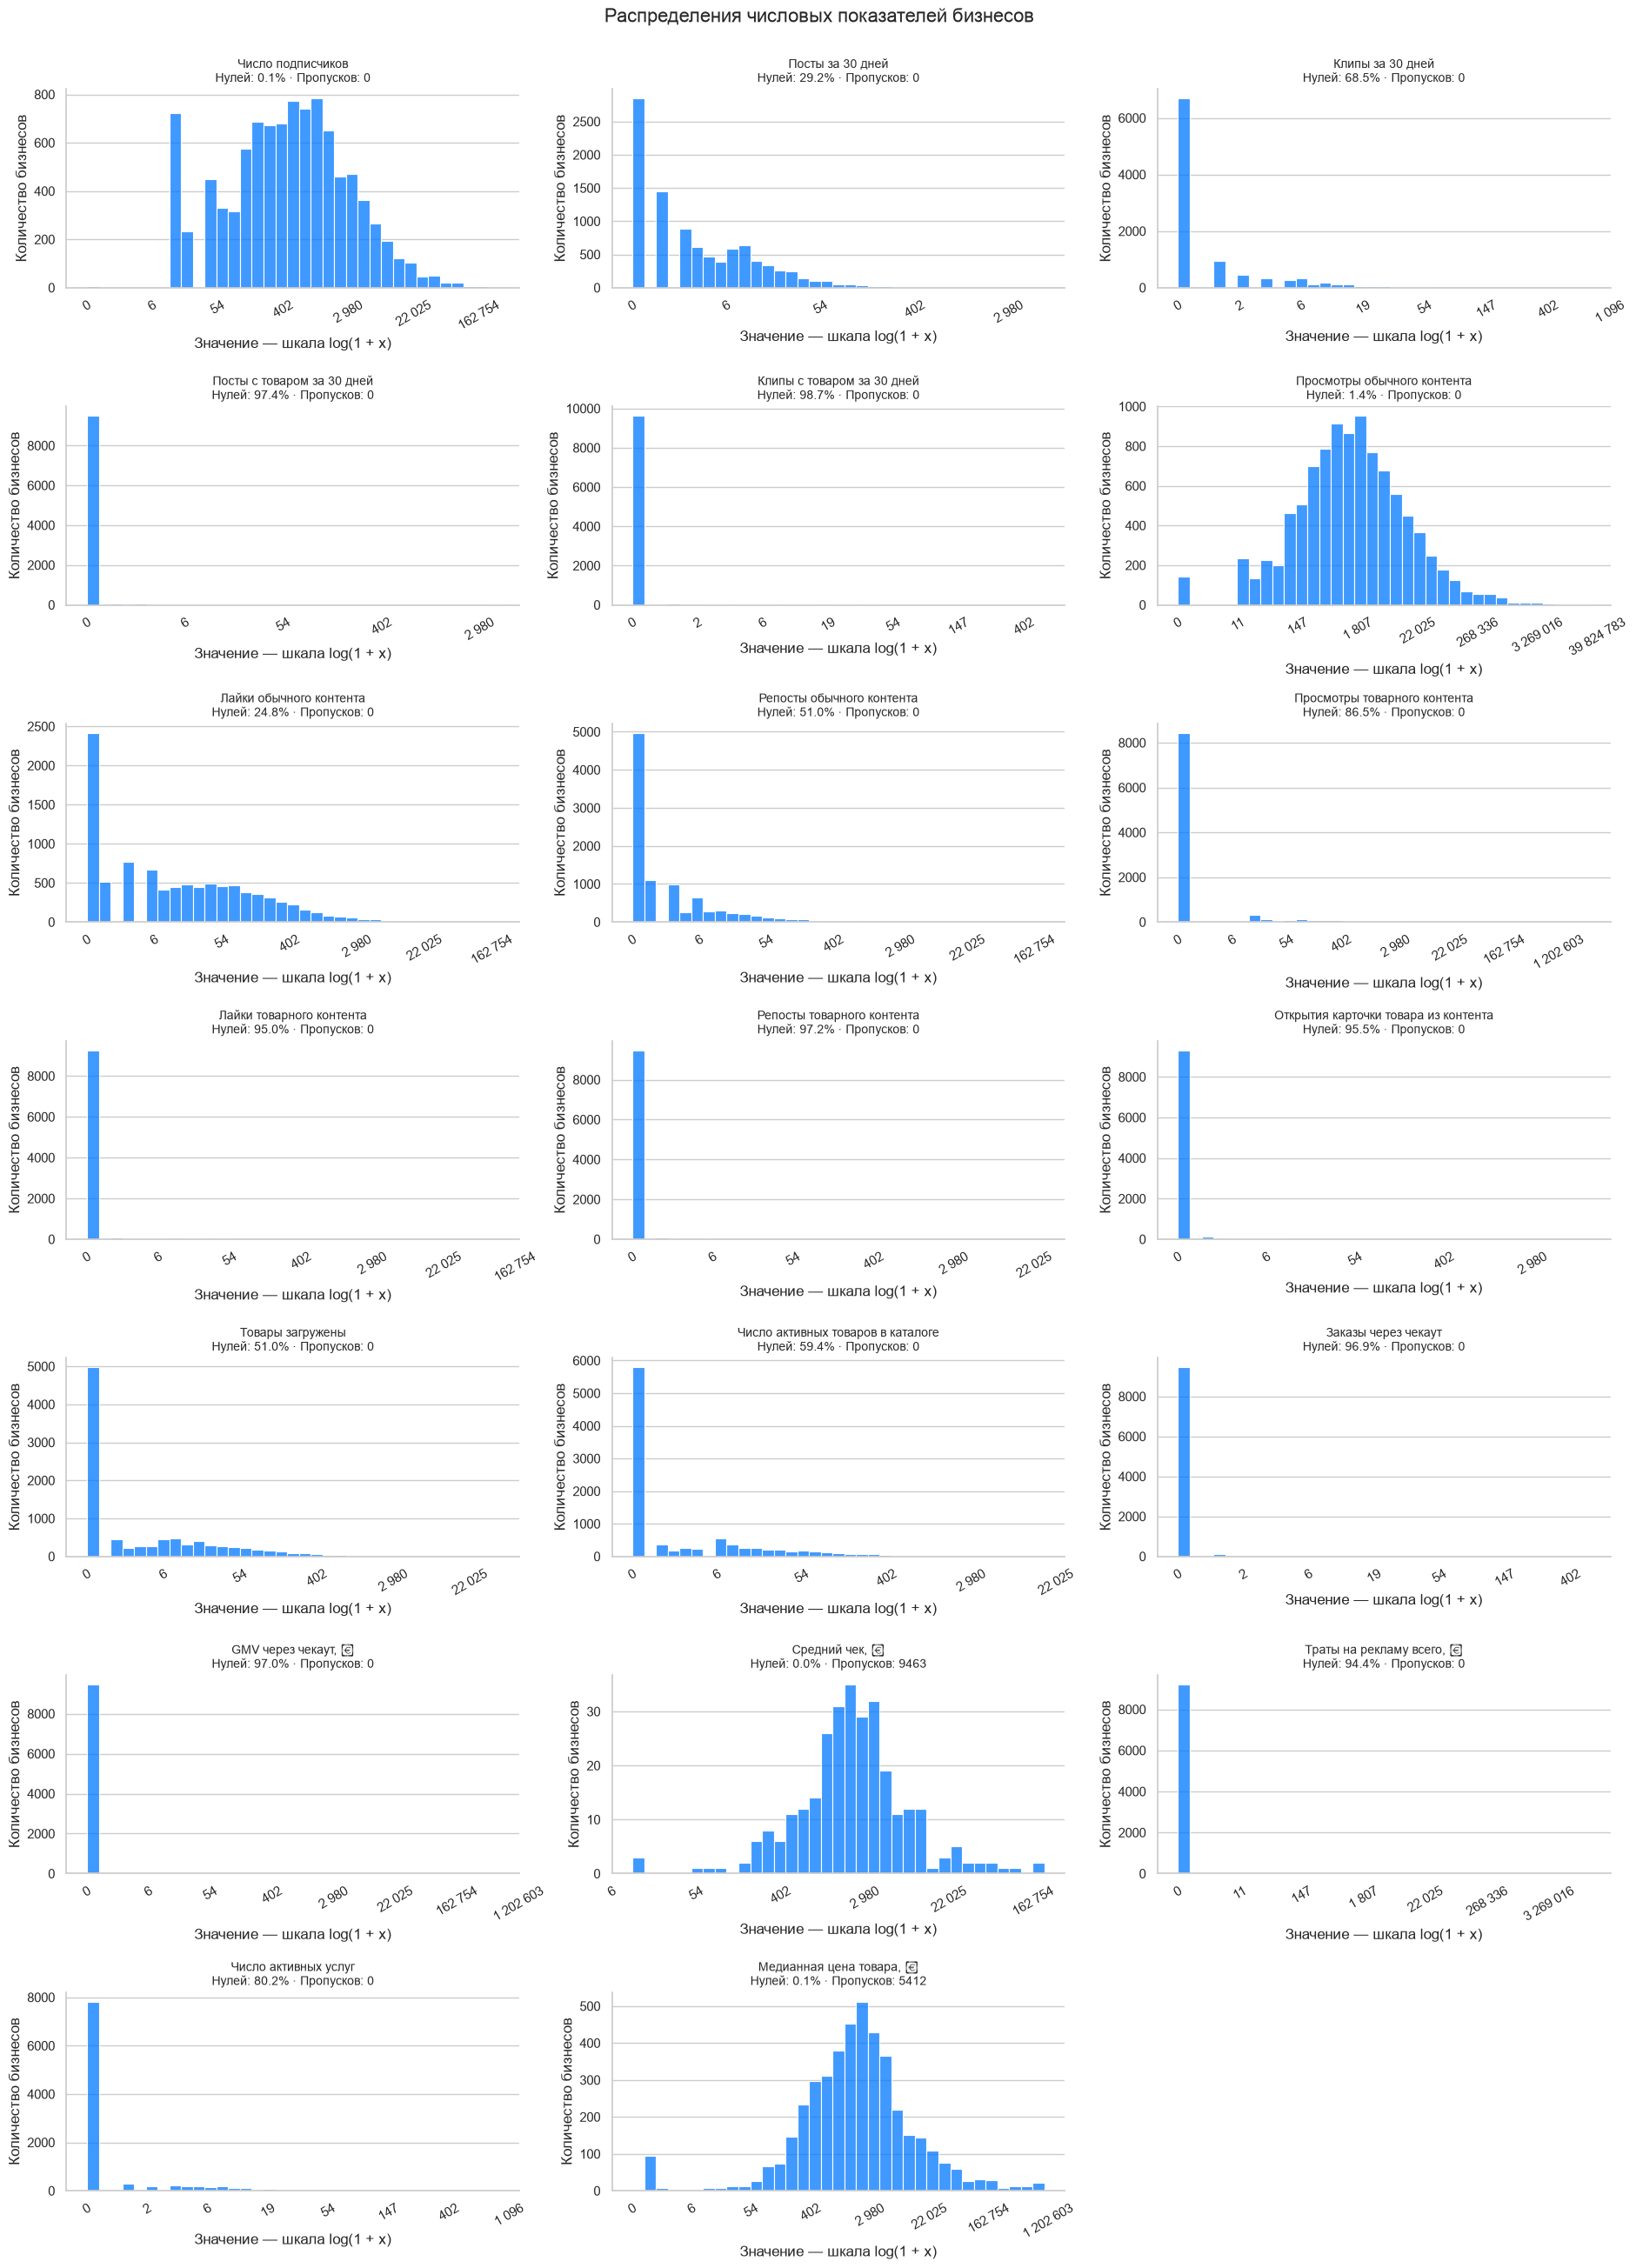

In [21]:
from pandas.api.types import is_numeric_dtype, is_bool_dtype

numeric_columns = [
    column for column in businesses.columns
    if is_numeric_dtype(businesses[column])
    and not is_bool_dtype(businesses[column])
    and column != "ID бизнеса"
]

ncols = 3
nrows = int(np.ceil(len(numeric_columns) / ncols))

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(19, 3.8 * nrows),
    squeeze=False,
)

for ax, column in zip(axes.flat, numeric_columns):
    values = businesses[column].dropna().astype(float)

    if values.empty:
        ax.set_title(column)
        ax.text(
            0.5, 0.5, "Нет данных",
            ha="center", va="center",
            transform=ax.transAxes,
        )
        continue

    # Для неотрицательных показателей сохраняем нули,
    # одновременно сжимая длинный правый хвост.
    use_log = values.ge(0).all()
    plot_values = np.log1p(values) if use_log else values

    sns.histplot(
        x=plot_values,
        bins=35,
        color="#0077FF",
        edgecolor="white",
        ax=ax,
    )

    if use_log:
        ax.xaxis.set_major_formatter(
            FuncFormatter(
                lambda x, _: f"{np.expm1(x):,.0f}".replace(",", " ")
            )
        )

    zero_share = values.eq(0).mean() * 100

    ax.set_title(
        f"{column}\n"
        f"Нулей: {zero_share:.1f}% · Пропусков: "
        f"{businesses[column].isna().sum()}",
        fontsize=10,
    )
    ax.set_xlabel(
        "Значение — шкала log(1 + x)" if use_log else "Значение"
    )
    ax.set_ylabel("Количество бизнесов")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="x", visible=False)

for ax in list(axes.flat)[len(numeric_columns):]:
    ax.set_visible(False)

sns.despine(fig=fig)
fig.suptitle("Распределения числовых показателей бизнесов", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

## Категориальные признаки и флаги

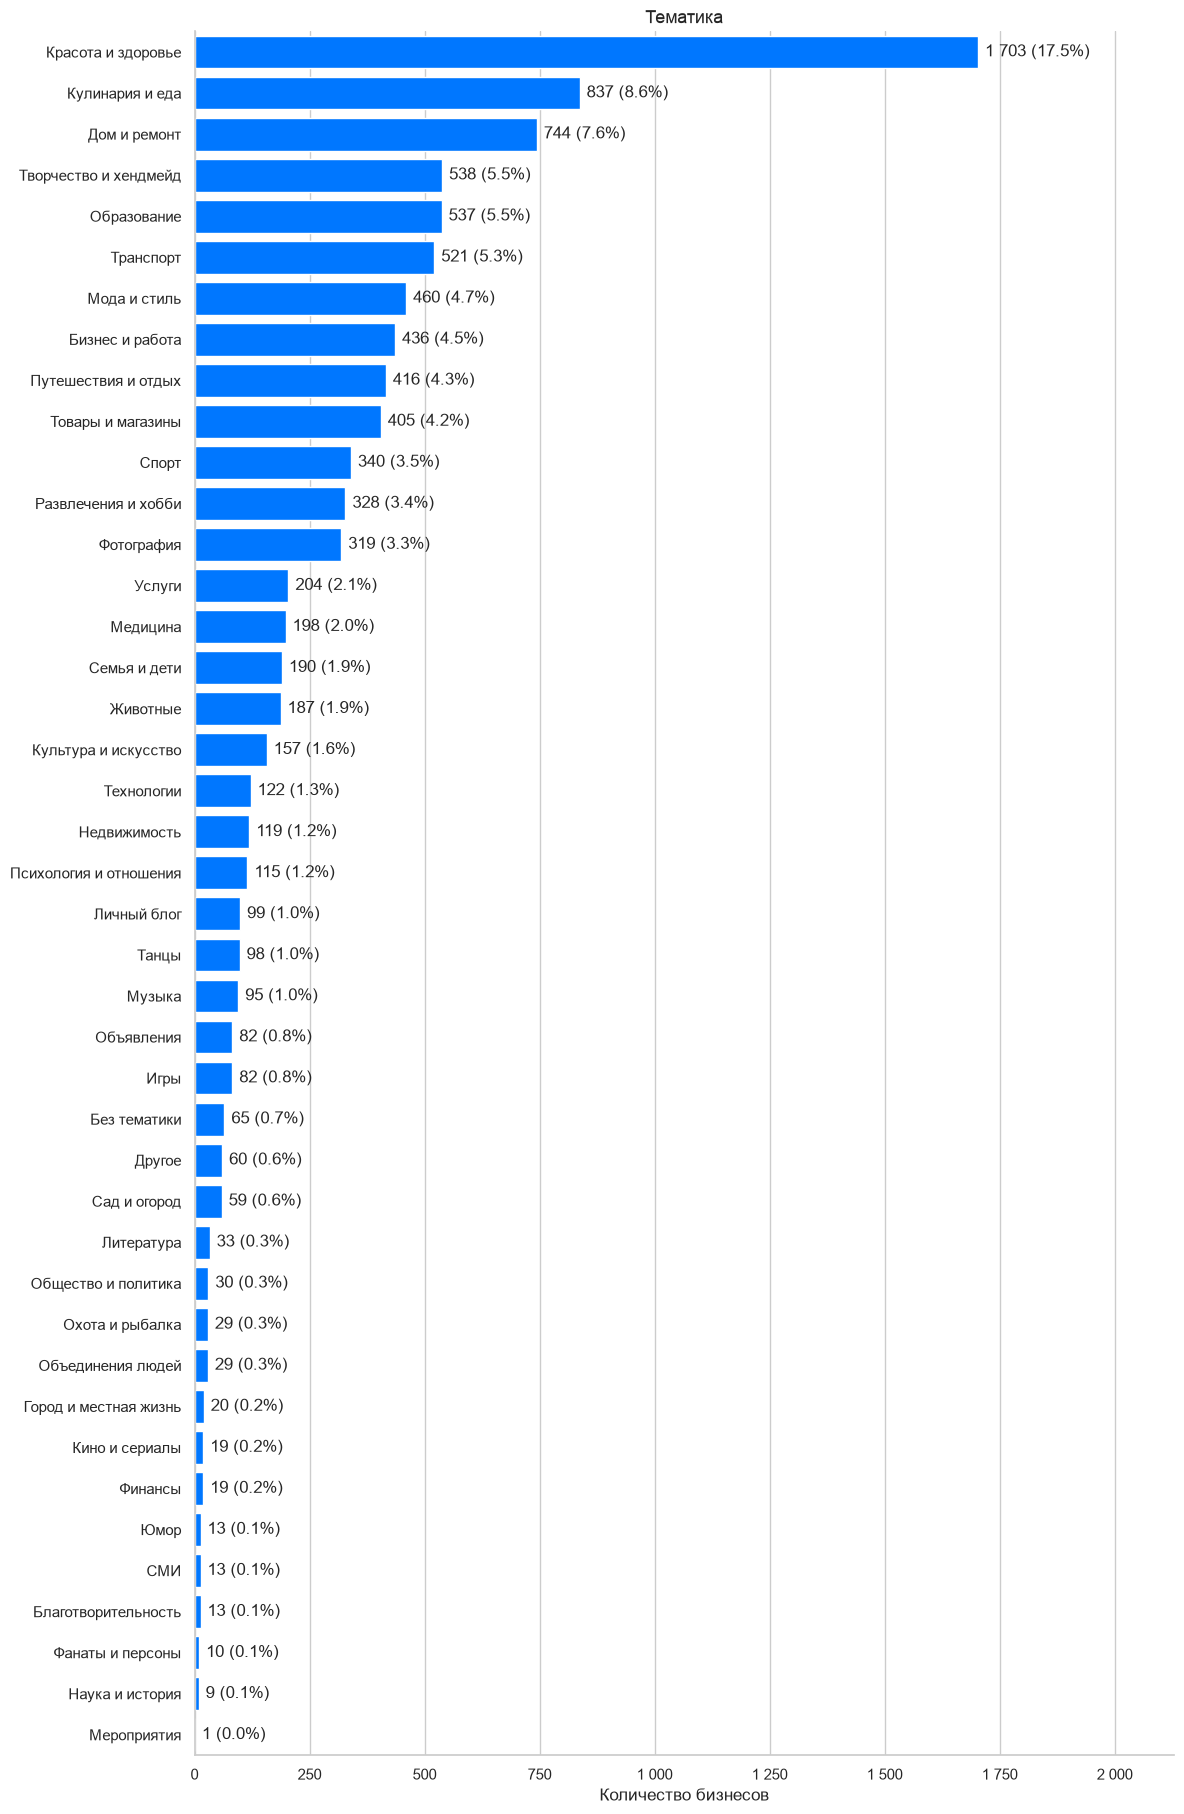

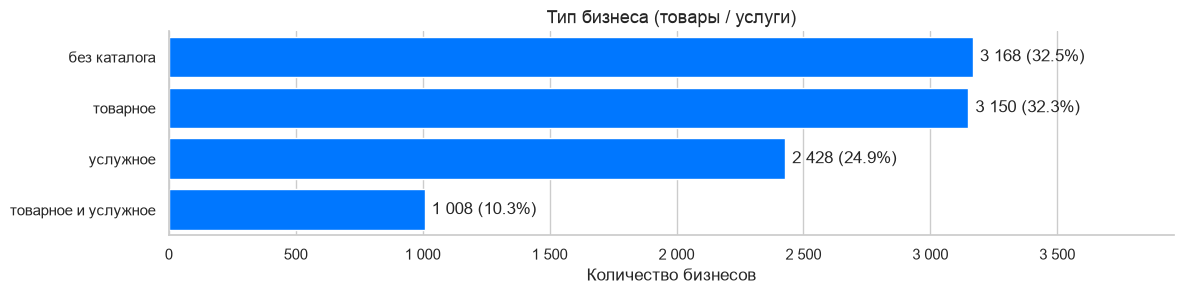

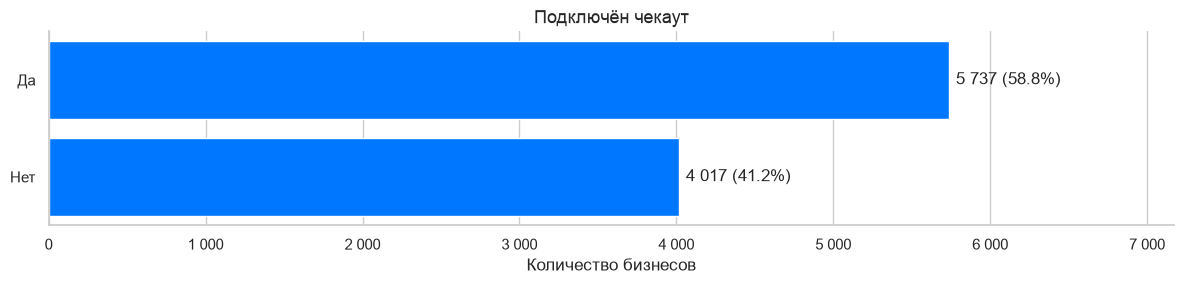

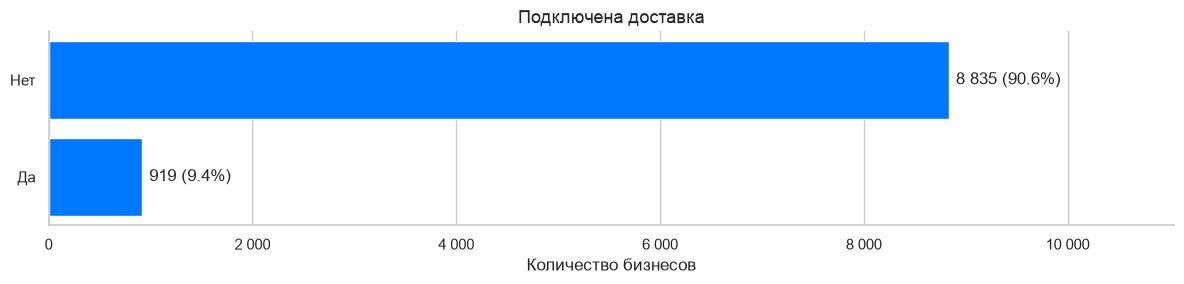

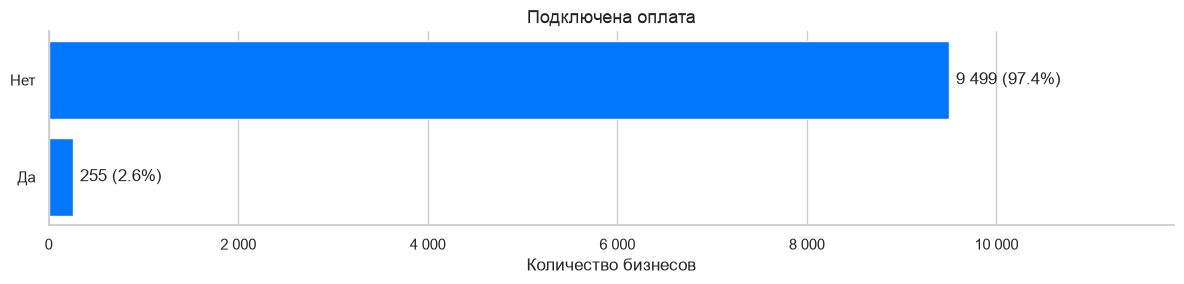

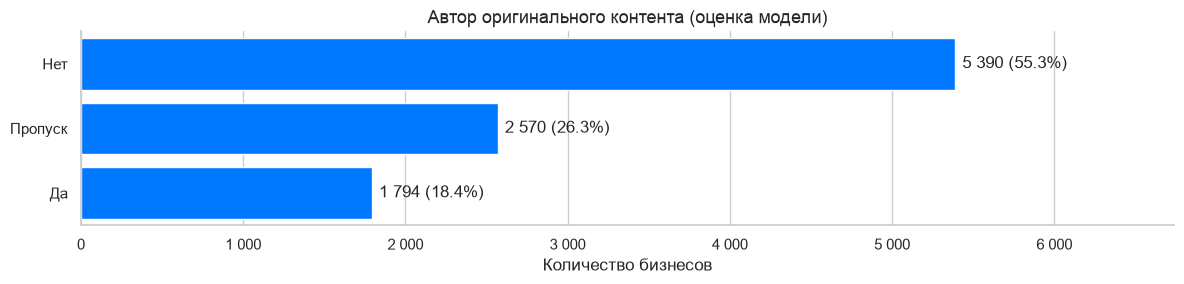

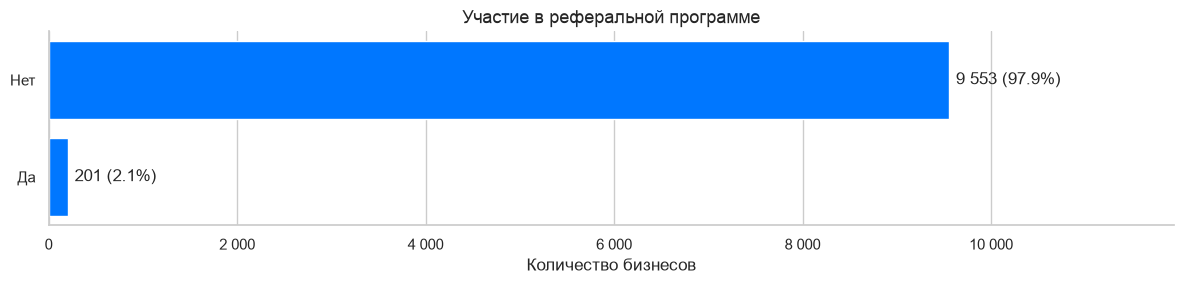

In [22]:
categorical_columns = [
    column for column in businesses.columns
    if (
        not is_numeric_dtype(businesses[column])
        or is_bool_dtype(businesses[column])
    )
    and column != "ID бизнеса"
]

for column in categorical_columns:
    if is_bool_dtype(businesses[column]):
        labels = businesses[column].map({
            True: "Да",
            False: "Нет",
        }).astype("string")
    else:
        labels = businesses[column].astype("string")

    labels = labels.fillna("Пропуск")

    counts = (
        labels.value_counts()
        .rename_axis("Значение")
        .reset_index(name="Бизнесов")
    )
    counts["Доля, %"] = 100 * counts["Бизнесов"] / len(businesses)

    fig, ax = plt.subplots(
        figsize=(12, max(3, len(counts) * 0.4 + 1.5))
    )

    sns.barplot(
        data=counts,
        x="Бизнесов",
        y="Значение",
        order=counts["Значение"].tolist(),
        color="#0077FF",
        saturation=1,
        ax=ax,
    )

    bar_labels = [
        f"{count:,} ({share:.1f}%)".replace(",", " ")
        for count, share in zip(counts["Бизнесов"], counts["Доля, %"])
    ]
    ax.bar_label(ax.containers[0], labels=bar_labels, padding=5)

    ax.set_title(column, fontsize=13)
    ax.set_xlabel("Количество бизнесов")
    ax.set_ylabel("")
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))
    )
    ax.margins(x=0.25)
    ax.grid(axis="y", visible=False)

    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

В выборке **9 754 бизнеса**. Большинство числовых показателей имеют много нулей и длинный правый хвост: среднее заметно выше значений типичного бизнеса.

**Числовые показатели:**

- **Аудитория преимущественно небольшая:** медиана — **490 подписчиков**, среднее — 2 482; у 75% бизнесов не более 1 700 подписчиков.
- **Контентная активность невысокая:** медиана — **2 поста и 0 клипов за месяц**. Товарные посты отсутствуют у **97,4%**, товарные клипы — у **98,7%** бизнесов.
- **Торговая активность редкая:** у **59,4%** нет активных товаров в каталоге, у **95,5%** — открытий карточек из контента. Заказы через чекаут есть только у **298 бизнесов — 3,1% выборки**.
- **Результат сильно сконцентрирован:** топ-1% бизнесов обеспечивают **91,0% заказов и 91,7% GMV**. Даже среди продающих бизнесов медиана — всего **2 заказа**.
- **Рекламные расходы есть у 5,6% бизнесов.** Средние расходы по всей выборке — 9 469 ₽ при нулевой медиане, поэтому среднее плохо описывает типичный бизнес.

**Категориальные признаки и флаги:**

| Признак | Доля бизнесов |
|---|---:|
| Без каталога | 32,5% |
| Товарные | 32,3% |
| Услужные | 24,9% |
| Товары и услуги | 10,3% |
| Подключён чекаут | 58,8% |
| Подключена доставка | 9,4% |
| Подключена оплата | 2,6% |
| Участие в реферальной программе | 2,1% |

Крупнейшая тематика — **«Красота и здоровье» (17,5%)**, далее «Кулинария и еда» (8,6%) и «Дом и ремонт» (7,6%).

**Выводы:** подключение торговых инструментов распространено значительно шире, чем фактические заказы через чекаут.

Все доли выше рассчитаны по общей выборке, включая услуги и бизнесы без каталога. Отсутствие заказов через чекаут не означает отсутствие продаж другими способами. Флаг оригинального контента неизвестен у **26,3%** бизнесов — пропуски нельзя считать ответом «нет».

## Состав бизнесов: типы и тематики

Тип бизнеса (товары / услуги),без каталога,товарное,товарное и услужное,услужное,Всего
Тематика,,,,,
Красота и здоровье,450,238,206,809,1703
Кулинария и еда,315,440,46,36,837
Дом и ремонт,231,293,92,128,744
Творчество и хендмейд,170,241,59,68,538
Образование,123,153,63,198,537
Транспорт,168,167,49,137,521
Мода и стиль,175,236,33,16,460
Бизнес и работа,161,127,43,105,436
Путешествия и отдых,126,131,68,91,416


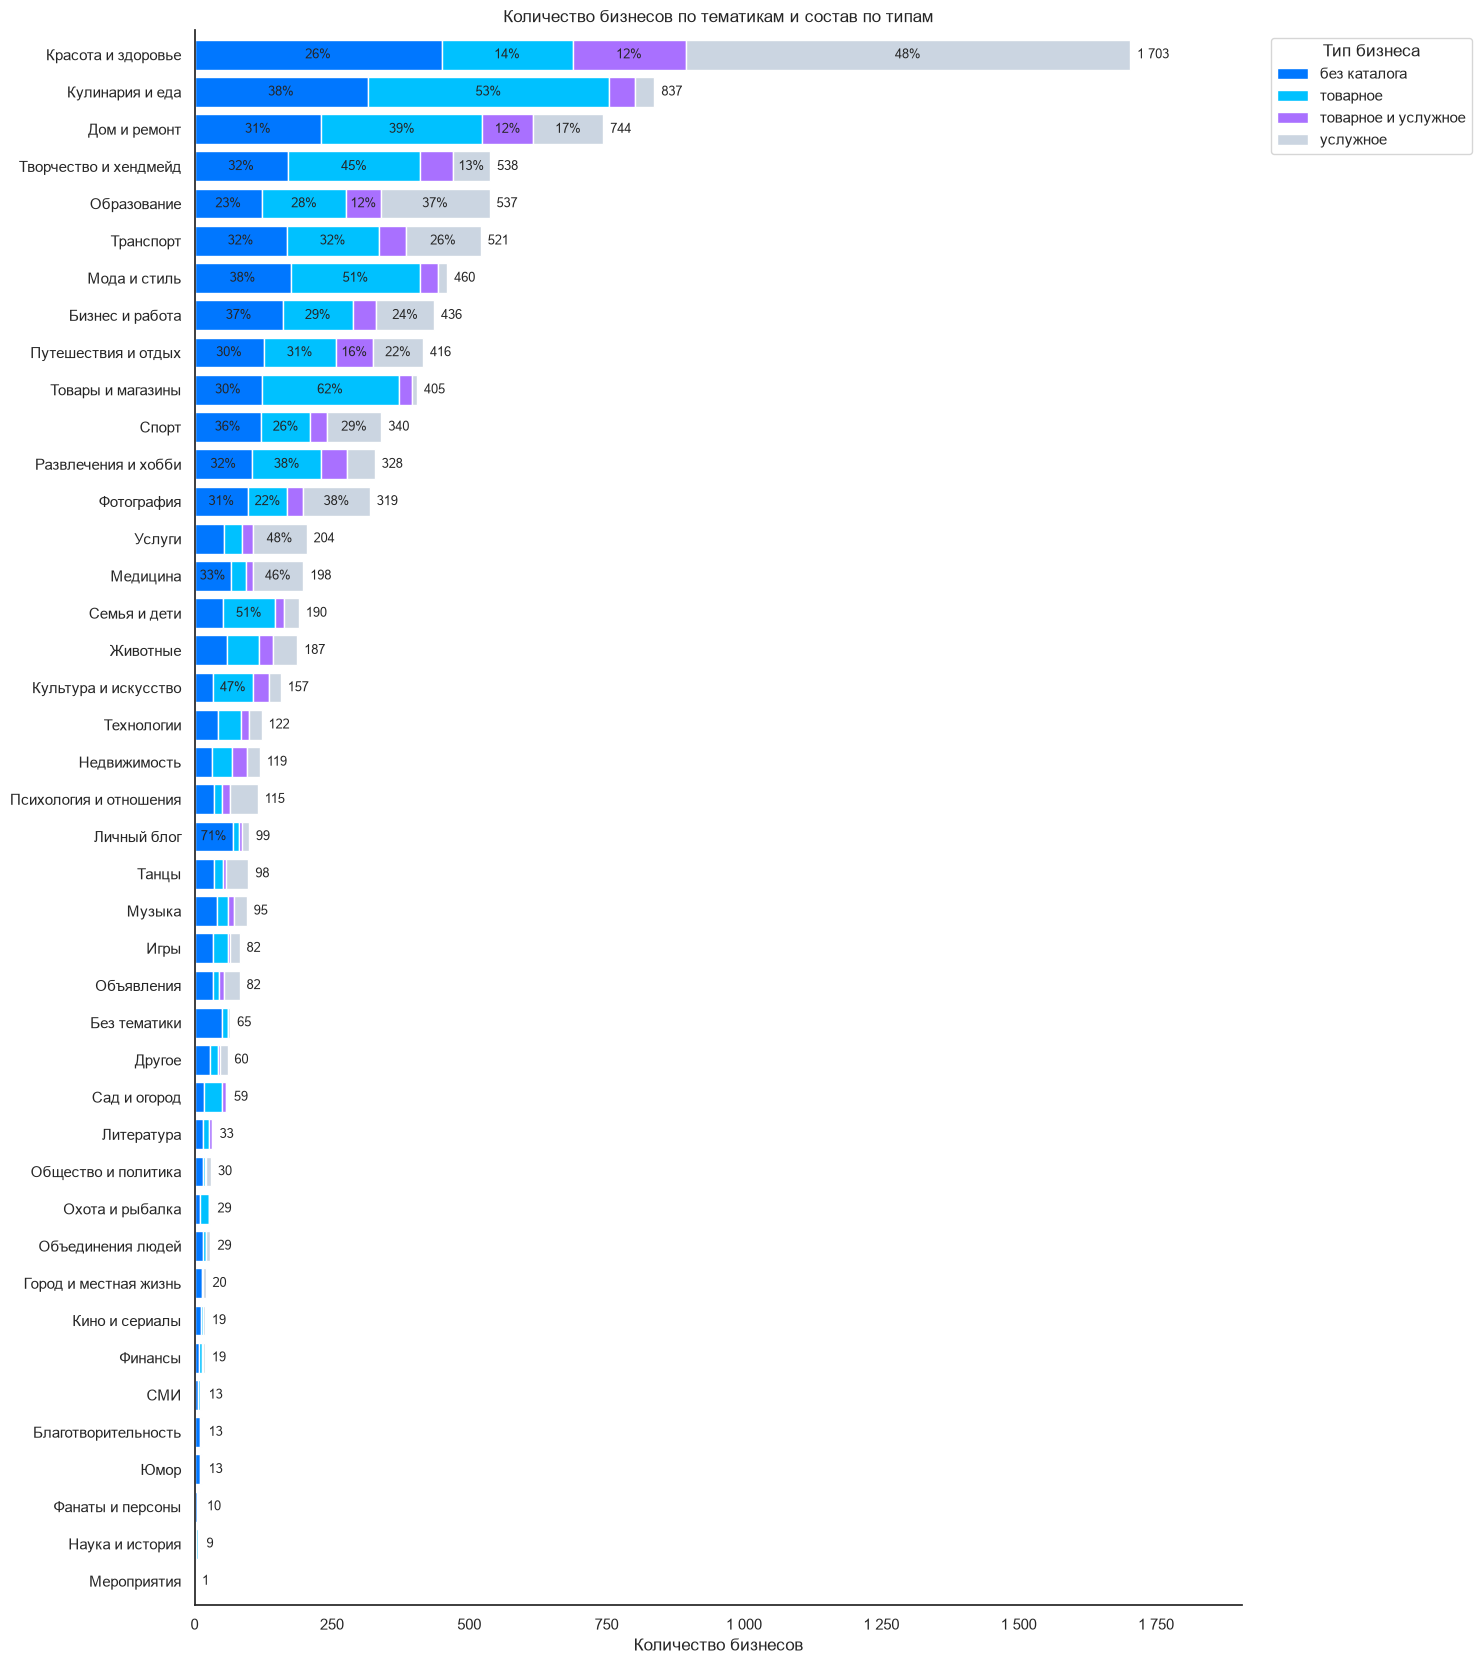

In [36]:
type_col = "Тип бизнеса (товары / услуги)"

theme_type_counts = pd.crosstab(
    businesses["Тематика"].fillna("Не указана"),
    businesses[type_col].fillna("Не указан"),
)

theme_type_counts["Всего"] = theme_type_counts.sum(axis=1)
theme_type_counts = theme_type_counts.sort_values("Всего", ascending=False)

display(theme_type_counts)

type_counts = theme_type_counts.drop(columns="Всего")
totals = type_counts.sum(axis=1)

ax = type_counts.plot.barh(
    stacked=True,
    figsize=(15, max(6, len(type_counts) * 0.4)),
    color=["#0077FF", "#00C1FF", "#A970FF", "#CBD5E1"],
    width=0.8,
)

for container in ax.containers:
    labels = []
    for bar, total in zip(container, totals):
        share = 100 * bar.get_width() / total if total else 0
        labels.append(
            f"{share:.0f}%"
            if share >= 7 and bar.get_width() >= totals.max() * 0.035
            else ""
        )

    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9,
    )

ax.bar_label(
    ax.containers[-1],
    labels=[f"{total:,.0f}".replace(",", " ") for total in totals],
    padding=5,
    fontsize=9,
)

ax.invert_yaxis()
ax.set(
    title="Количество бизнесов по тематикам и состав по типам",
    xlabel="Количество бизнесов",
    ylabel="",
)
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:,.0f}".replace(",", " "))
)
ax.margins(x=0.12)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.legend(
    title="Тип бизнеса",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

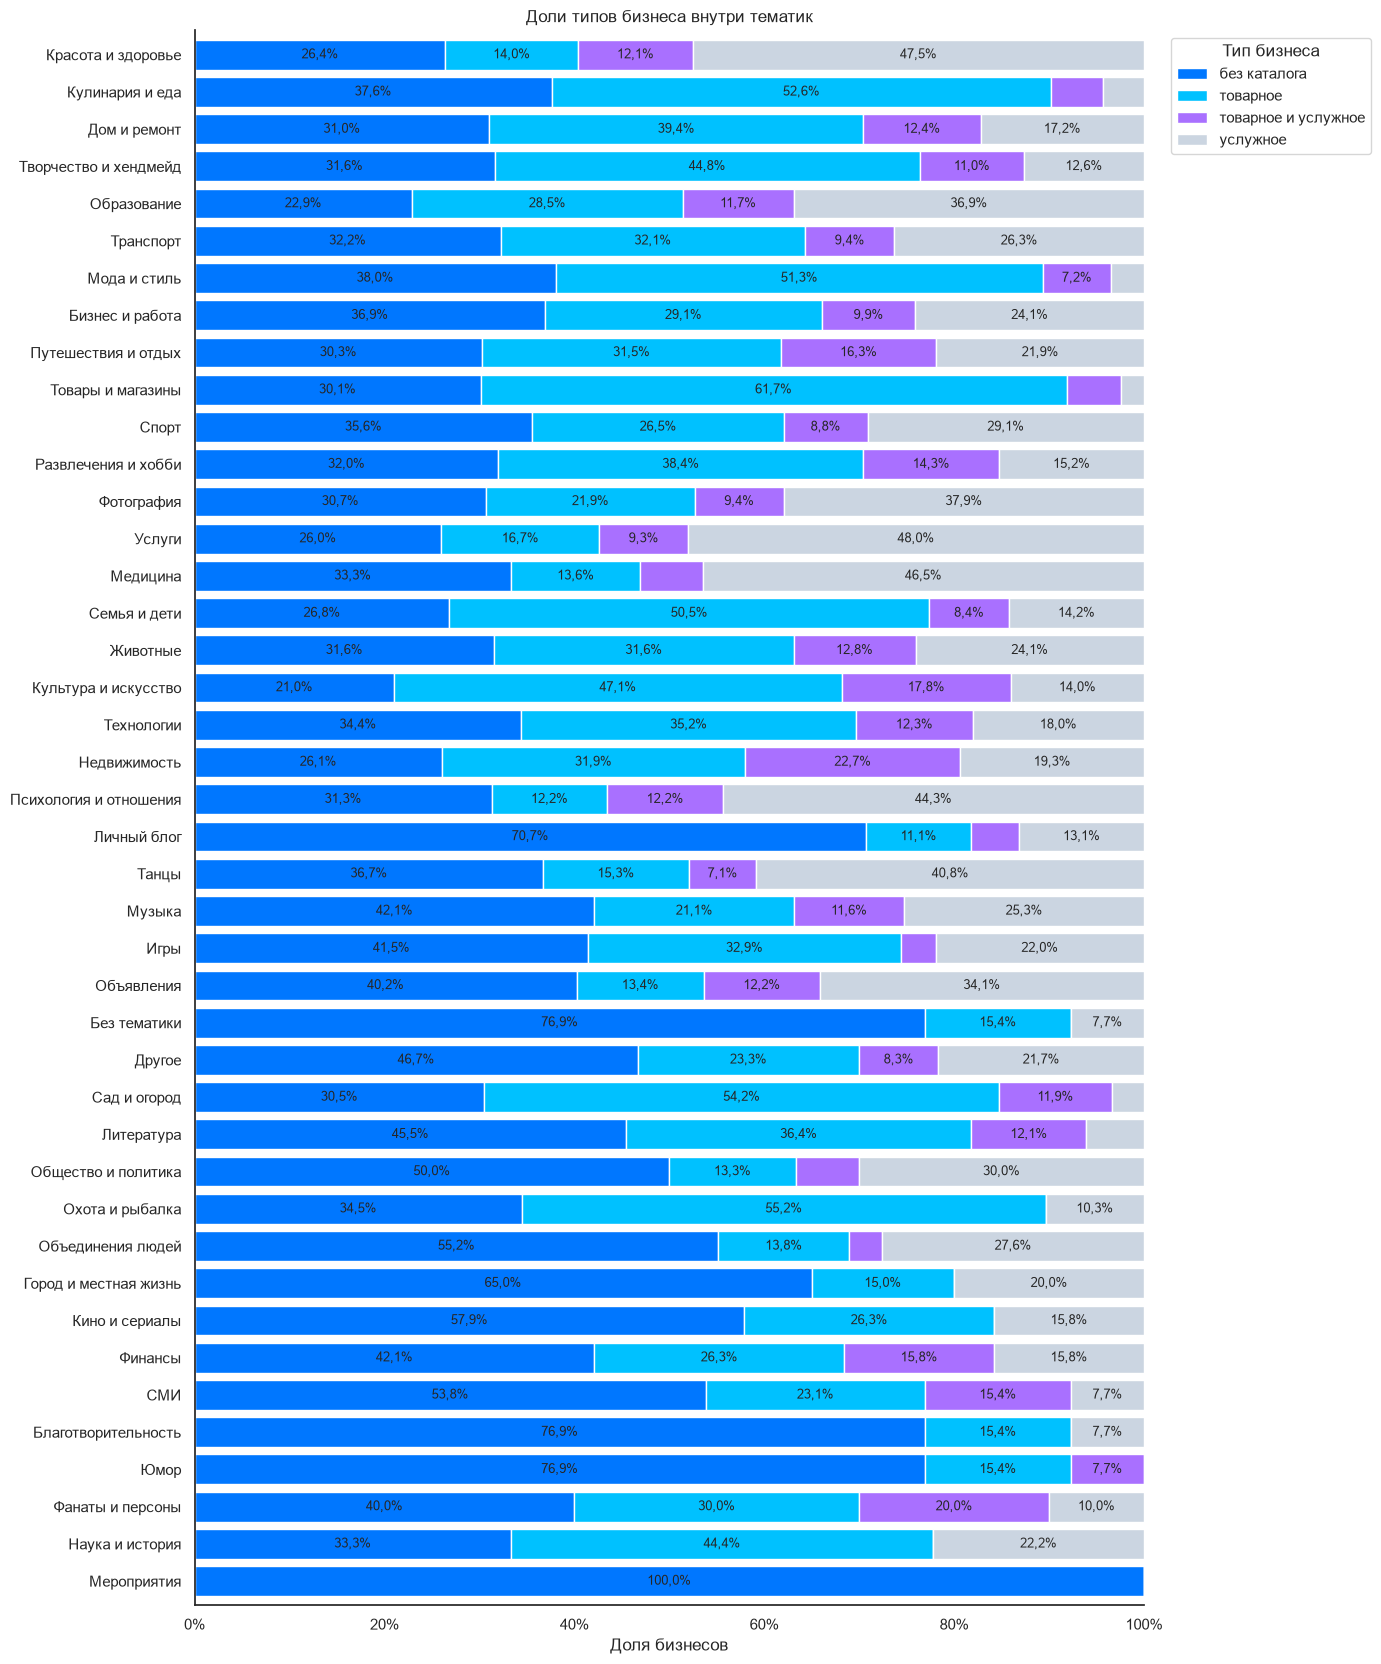

In [37]:
type_counts = theme_type_counts.drop(columns="Всего")
type_shares = type_counts.div(type_counts.sum(axis=1), axis=0) * 100

ax = type_shares.plot.barh(
    stacked=True,
    figsize=(14, max(6, len(type_shares) * 0.4)),
    color=["#0077FF", "#00C1FF", "#A970FF", "#CBD5E1"],
    width=0.8,
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f"{bar.get_width():.1f}%".replace(".", ",")
            if bar.get_width() >= 7 else ""
            for bar in container
        ],
        label_type="center",
        fontsize=9,
    )

ax.invert_yaxis()
ax.set(
    title="Доли типов бизнеса внутри тематик",
    xlabel="Доля бизнесов",
    ylabel="",
    xlim=(0, 100),
)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.legend(title="Тип бизнеса", bbox_to_anchor=(1.02, 1), loc="upper left")

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

In [38]:
theme_type_summary = theme_type_counts.drop(columns="Всего").copy()

theme_type_summary["Всего бизнесов"] = theme_type_summary.sum(axis=1)
theme_type_summary["Товарные и смешанные"] = (
    theme_type_summary["товарное"]
    + theme_type_summary["товарное и услужное"]
)

for column in [
    "без каталога",
    "товарное",
    "товарное и услужное",
    "услужное",
    "Товарные и смешанные",
]:
    theme_type_summary[f"{column}: доля внутри тематики, %"] = (
        100
        * theme_type_summary[column]
        / theme_type_summary["Всего бизнесов"]
    )

theme_type_summary["Доля тематики в выборке, %"] = (
    100
    * theme_type_summary["Всего бизнесов"]
    / theme_type_summary["Всего бизнесов"].sum()
)

theme_type_summary = theme_type_summary.sort_values(
    "Всего бизнесов", ascending=False
)

display(theme_type_summary.round(2))

Тип бизнеса (товары / услуги),без каталога,товарное,товарное и услужное,услужное,Всего бизнесов,Товарные и смешанные,"без каталога: доля внутри тематики, %","товарное: доля внутри тематики, %","товарное и услужное: доля внутри тематики, %","услужное: доля внутри тематики, %","Товарные и смешанные: доля внутри тематики, %","Доля тематики в выборке, %"
Тематика,,,,,,,,,,,,
Красота и здоровье,450,238,206,809,1703,444,26.42,13.98,12.10,47.50,26.07,17.46
Кулинария и еда,315,440,46,36,837,486,37.63,52.57,5.50,4.30,58.06,8.58
Дом и ремонт,231,293,92,128,744,385,31.05,39.38,12.37,17.20,51.75,7.63
Творчество и хендмейд,170,241,59,68,538,300,31.60,44.80,10.97,12.64,55.76,5.52
Образование,123,153,63,198,537,216,22.91,28.49,11.73,36.87,40.22,5.51
Транспорт,168,167,49,137,521,216,32.25,32.05,9.40,26.30,41.46,5.34
Мода и стиль,175,236,33,16,460,269,38.04,51.30,7.17,3.48,58.48,4.72
Бизнес и работа,161,127,43,105,436,170,36.93,29.13,9.86,24.08,38.99,4.47
Путешествия и отдых,126,131,68,91,416,199,30.29,31.49,16.35,21.88,47.84,4.26


**Ключевые выводы:**
- "Красота и здоровье" — крупнейшая тематика, но преимущественно услужная: услуги составляют 47,5%. Для товарного сценария доступная группа здесь меньше, чем в «Кулинарии и еде».
- Еда, дом и хендмейд — крупные группы для исследования товарных сценариев: соответственно 486, 385 и 300 товарных и смешанных бизнесов.
- "Товары и магазины" и "Мода и стиль" меньше по общему размеру, но имеют высокую долю товарных и смешанных бизнесов — 67,4% и 58,5%.
- Бизнесы без каталога — отдельный сегмент: 3 168 сообществ, или 32,5% выборки. Для них сначала нужно выяснить потребность в каталоге и причины его отсутствия.

## Торговые инструменты и наличие продаж — отдельно по типам бизнеса

In [24]:
orders_col = "Заказы через чекаут"
gmv_col = "GMV через чекаут, ₽"

business_analysis = businesses.copy()

business_analysis["Есть заказы"] = (
    business_analysis[orders_col].gt(0)
    .astype("boolean")
    .where(business_analysis[orders_col].notna())
)
business_analysis["Есть активные товары"] = (
    business_analysis["Число активных товаров в каталоге"].gt(0)
    .astype("boolean")
    .where(business_analysis["Число активных товаров в каталоге"].notna())
)

flags = [
    "Есть активные товары",
    "Подключён чекаут",
    "Подключена оплата",
    "Подключена доставка",
    "Есть заказы",
    "Автор оригинального контента (оценка модели)",
    "Участие в реферальной программе",
]

flag_summary = pd.DataFrame({
    "Известно значений": business_analysis[flags].count(),
    "Бизнесов с признаком": business_analysis[flags].sum(min_count=1),
    "Доля среди известных, %": business_analysis[flags].mean() * 100,
})

display(flag_summary.round(2))

sales_by_type = (
    business_analysis
    .groupby(type_col, dropna=False)
    .agg(
        Бизнесов=("ID бизнеса", "size"),
        Бизнесов_с_заказами=("Есть заказы", lambda s: s.sum(min_count=1)),
        Доля_с_заказами=("Есть заказы", "mean"),
        Доля_с_чекаутом=("Подключён чекаут", "mean"),
        Доля_с_оплатой=("Подключена оплата", "mean"),
        Доля_с_доставкой=("Подключена доставка", "mean"),
        Заказов=(orders_col, lambda s: s.sum(min_count=1)),
        GMV=(gmv_col, lambda s: s.sum(min_count=1)),
    )
    .reset_index()
)

share_columns = [
    "Доля_с_заказами",
    "Доля_с_чекаутом",
    "Доля_с_оплатой",
    "Доля_с_доставкой",
]
sales_by_type[share_columns] *= 100
sales_by_type = sales_by_type.rename(
    columns={col: f"{col}, %" for col in share_columns}
)

display(sales_by_type.round(2))

,Известно значений,Бизнесов с признаком,"Доля среди известных, %"
Есть активные товары,9754,3961,40.61
Подключён чекаут,9754,5737,58.82
Подключена оплата,9754,255,2.61
Подключена доставка,9754,919,9.42
Есть заказы,9754,298,3.06
Автор оригинального контента (оценка модели),7184,1794,24.97
Участие в реферальной программе,9754,201,2.06


,Тип бизнеса (товары / услуги),Бизнесов,Бизнесов_с_заказами,"Доля_с_заказами, %","Доля_с_чекаутом, %","Доля_с_оплатой, %","Доля_с_доставкой, %",Заказов,GMV
0,без каталога,3168,10,0.32,35.01,0.54,0.92,16,93650.0
1,товарное,3150,241,7.65,91.90,5.24,19.84,3207,8720487.0
2,товарное и услужное,1008,44,4.37,92.36,5.06,19.15,251,1144580.0
3,услужное,2428,3,0.12,33.03,0.91,2.97,4,14310.0


**Главный вывод:** у товарных бизнесов чекаут уже широко подключён, но заказы через него получают немногие.

- Товарные бизнесы — основная группа для исследования продаж через чекаут: они обеспечивают 92,2% заказов выборки. Услуги и бизнесы без каталога требуют отдельного сценария анализа.
- Подключение не означает регулярное использование. Среди товарных бизнесов 2 658 имеют включённый чекаут, но не имеют заказов за период. Это крупная группа для дальнейшего разделения: есть ли активные товары, просмотры и открытия карточек.
- У смешанных бизнесов доля продающих ниже: 4,37% против 7,65% у товарных, хотя подключение чекаута практически одинаковое. Само наличие чекаута не объясняет разницу.

В слудующей ячейки подразуемвается продажа через чекаут

In [40]:
type_col = "Тип бизнеса (товары / услуги)"
orders_col = "Заказы через чекаут"
products_col = "Число активных товаров в каталоге"
opens_col = "Открытия карточки товара из контента"

no_sales = businesses.loc[
    businesses[type_col].eq("товарное")
    & businesses[orders_col].eq(0)
].copy()

# Не приравниваем неизвестные значения к нулю.
segmented = no_sales.dropna(
    subset=[products_col, opens_col]
).copy()

segment_order = [
    "Нет активных товаров",
    "Есть товары, нет открытий из контента",
    "Есть товары и открытия, нет заказов",
]

segmented["Сегмент"] = np.select(
    [
        segmented[products_col].eq(0),
        segmented[products_col].gt(0) & segmented[opens_col].eq(0),
    ],
    segment_order[:2],
    default=segment_order[2],
)

segment_summary = (
    segmented["Сегмент"]
    .value_counts()
    .reindex(segment_order, fill_value=0)
    .rename_axis("Сегмент")
    .reset_index(name="Бизнесов")
)

segment_summary["Доля среди классифицированных, %"] = (
    100 * segment_summary["Бизнесов"] / len(segmented)
    if len(segmented) else np.nan
)

print(f"Товарных бизнесов без заказов: {len(no_sales):,}")
print(f"Не классифицировано из-за пропусков: {len(no_sales) - len(segmented):,}")

display(segment_summary.round(2))

Товарных бизнесов без заказов: 2,909
Не классифицировано из-за пропусков: 0


,Сегмент,Бизнесов,"Доля среди классифицированных, %"
0,Нет активных товаров,144,4.95
1,"Есть товары, нет открытий из контента",2565,88.17
2,"Есть товары и открытия, нет заказов",200,6.88


## Распределение заказов среди продающих бизнесов и концентрация

Бизнесов с заказами: 298
Бизнесов с неизвестным числом заказов: 0


,count,mean,std,min,50%,90%,95%,99%,max
Заказы через чекаут,298.0,11.67,42.58,1.0,2.0,20.0,44.0,170.43,543.0
"GMV через чекаут, ₽",298.0,33466.53,84928.32,0.0,5765.0,66381.0,181405.0,465152.50,635250.0
"Средний чек, ₽",291.0,6461.29,19859.77,11.0,2231.0,10064.0,24188.0,88039.30,211758.0


,Показатель,Группа,Бизнесов в группе,База: бизнесов с известным значением,"Доля результата, %"
0,Заказы через чекаут,Топ-1%,98,9754,90.97
1,Заказы через чекаут,Топ-5%,488,9754,100.00
2,Заказы через чекаут,Топ-10%,976,9754,100.00
3,"GMV через чекаут, ₽",Топ-1%,98,9754,91.67
4,"GMV через чекаут, ₽",Топ-5%,488,9754,100.00
5,"GMV через чекаут, ₽",Топ-10%,976,9754,100.00


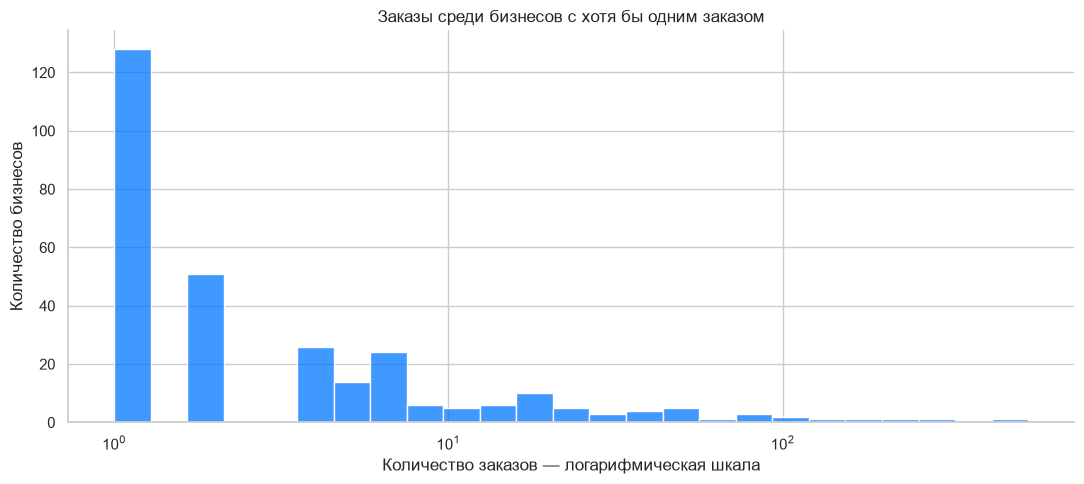

In [25]:
selling_businesses = businesses.loc[
    businesses[orders_col].gt(0)
].copy()

print(f"Бизнесов с заказами: {len(selling_businesses)}")
print(
    "Бизнесов с неизвестным числом заказов:",
    businesses[orders_col].isna().sum(),
)

display(
    selling_businesses[
        [orders_col, gmv_col, "Средний чек, ₽"]
    ]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .T
    .round(2)
)

# Для каждого показателя свой рейтинг бизнесов.
concentration_rows = []

for metric in [orders_col, gmv_col]:
    values = businesses[metric].dropna().sort_values(ascending=False)
    total = values.sum()

    for fraction in [0.01, 0.05, 0.10]:
        top_n = max(1, int(np.ceil(len(values) * fraction)))

        concentration_rows.append({
            "Показатель": metric,
            "Группа": f"Топ-{fraction:.0%}",
            "Бизнесов в группе": top_n,
            "База: бизнесов с известным значением": len(values),
            "Доля результата, %": (
                100 * values.head(top_n).sum() / total
                if total > 0 else np.nan
            ),
        })

display(pd.DataFrame(concentration_rows).round(2))

if not selling_businesses.empty:
    fig, ax = plt.subplots(figsize=(11, 5))

    sns.histplot(
        data=selling_businesses,
        x=orders_col,
        bins=25,
        log_scale=True,
        color="#0077FF",
        ax=ax,
    )

    ax.set_title("Заказы среди бизнесов с хотя бы одним заказом")
    ax.set_xlabel("Количество заказов — логарифмическая шкала")
    ax.set_ylabel("Количество бизнесов")
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

## Контент и реклама: насколько распространено использование

In [26]:
activity_columns = [
    "Посты за 30 дней",
    "Клипы за 30 дней",
    "Посты с товаром за 30 дней",
    "Клипы с товаром за 30 дней",
    "Просмотры обычного контента",
    "Просмотры товарного контента",
    "Открытия карточки товара из контента",
    "Траты на рекламу всего, ₽",
]

activity_rows = []

for column in activity_columns:
    values = businesses[column]
    positive = values.loc[values.gt(0)]

    activity_rows.append({
        "Показатель": column,
        "Известно значений": values.notna().sum(),
        "Бизнесов со значением > 0": len(positive),
        "Доля > 0 среди известных, %": (
            100 * len(positive) / values.notna().sum()
            if values.notna().any() else np.nan
        ),
        "Медиана среди всех заполненных": values.median(),
        "Медиана среди положительных": positive.median(),
        "P90 среди положительных": positive.quantile(0.9),
    })

display(pd.DataFrame(activity_rows).round(2))

,Показатель,Известно значений,Бизнесов со значением > 0,"Доля > 0 среди известных, %",Медиана среди всех заполненных,Медиана среди положительных,P90 среди положительных
0,Посты за 30 дней,9754,6908,70.82,2.0,6.0,30.0
1,Клипы за 30 дней,9754,3068,31.45,0.0,3.0,15.0
2,Посты с товаром за 30 дней,9754,258,2.65,0.0,2.0,17.3
3,Клипы с товаром за 30 дней,9754,123,1.26,0.0,2.0,12.8
4,Просмотры обычного контента,9754,9613,98.55,1300.0,1300.0,24800.0
5,Просмотры товарного контента,9754,1316,13.49,0.0,88.0,4350.0
6,Открытия карточки товара из контента,9754,437,4.48,0.0,3.0,54.0
7,"Траты на рекламу всего, ₽",9754,542,5.56,0.0,45000.0,310000.0


,Показатель,Известно значений,Бизнесов со значением > 0,"Доля > 0 среди известных, %",Медиана среди всех заполненных,Медиана среди положительных,P90 среди положительных
0,Посты за 30 дней,9754,6908,70.82,2.0,6.0,30.0
1,Клипы за 30 дней,9754,3068,31.45,0.0,3.0,15.0
2,Посты с товаром за 30 дней,9754,258,2.65,0.0,2.0,17.3
3,Клипы с товаром за 30 дней,9754,123,1.26,0.0,2.0,12.8
4,Просмотры обычного контента,9754,9613,98.55,1300.0,1300.0,24800.0
5,Просмотры товарного контента,9754,1316,13.49,0.0,88.0,4350.0
6,Открытия карточки товара из контента,9754,437,4.48,0.0,3.0,54.0
7,"Траты на рекламу всего, ₽",9754,542,5.56,0.0,45000.0,310000.0


/var/folders/_s/f68gy4zx0g73f0y2f_ldy2340000gn/T/ipykernel_2586/336436493.py:45: UserWarning: Glyph 8381 (\N{RUBLE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/savin/Documents/Projects/VK Case Champ 2026/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8381 (\N{RUBLE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


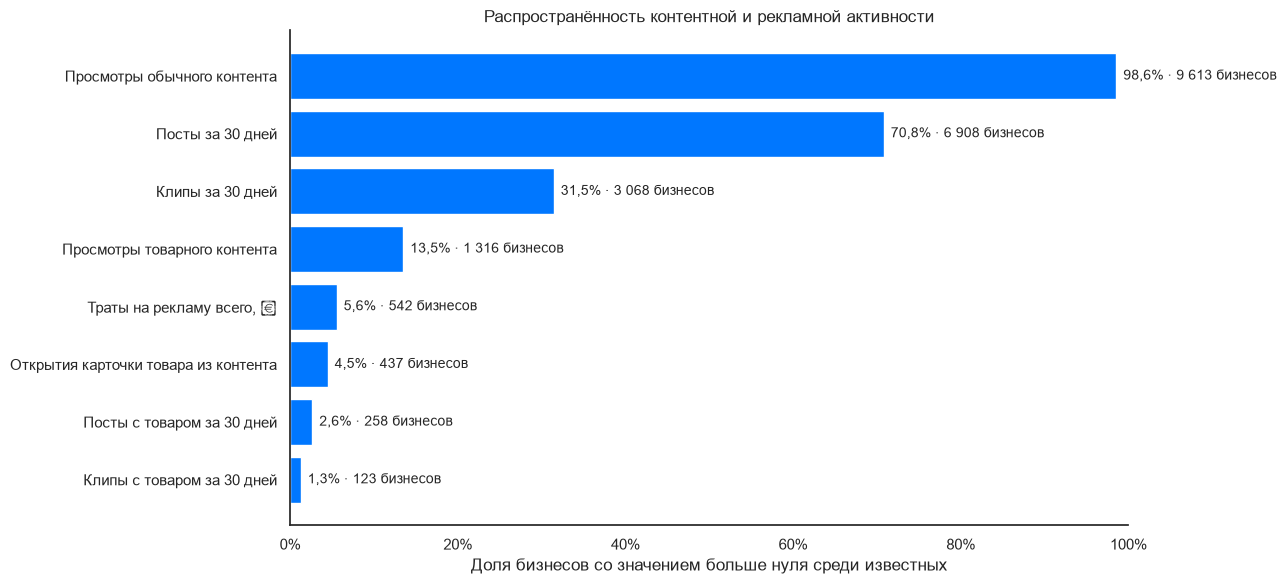

In [41]:
activity_summary = pd.DataFrame(activity_rows)

display(activity_summary.round(2))

plot_data = activity_summary.sort_values(
    "Доля > 0 среди известных, %", ascending=False
)

fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.barh(
    plot_data["Показатель"],
    plot_data["Доля > 0 среди известных, %"],
    color="#0077FF",
)

ax.bar_label(
    bars,
    labels=[
        f"{share:.1f}% · {count:,} бизнесов"
        .replace(",", " ")
        .replace(".", ",")
        if pd.notna(share) else "Нет данных"
        for share, count in zip(
            plot_data["Доля > 0 среди известных, %"],
            plot_data["Бизнесов со значением > 0"],
        )
    ],
    padding=5,
    fontsize=10,
)

ax.invert_yaxis()
ax.set(
    title="Распространённость контентной и рекламной активности",
    xlabel="Доля бизнесов со значением больше нуля среди известных",
    ylabel="",
    xlim=(0, 100),
)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

## Корреялционная матрица

/Users/savin/Documents/Projects/VK Case Champ 2026/.venv/lib/python3.13/site-packages/seaborn/utils.py:61: UserWarning: Glyph 8381 (\N{RUBLE SIGN}) missing from font(s) Arial.
  fig.canvas.draw()
/var/folders/_s/f68gy4zx0g73f0y2f_ldy2340000gn/T/ipykernel_2586/2718253817.py:71: UserWarning: Glyph 8381 (\N{RUBLE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/savin/Documents/Projects/VK Case Champ 2026/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8381 (\N{RUBLE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


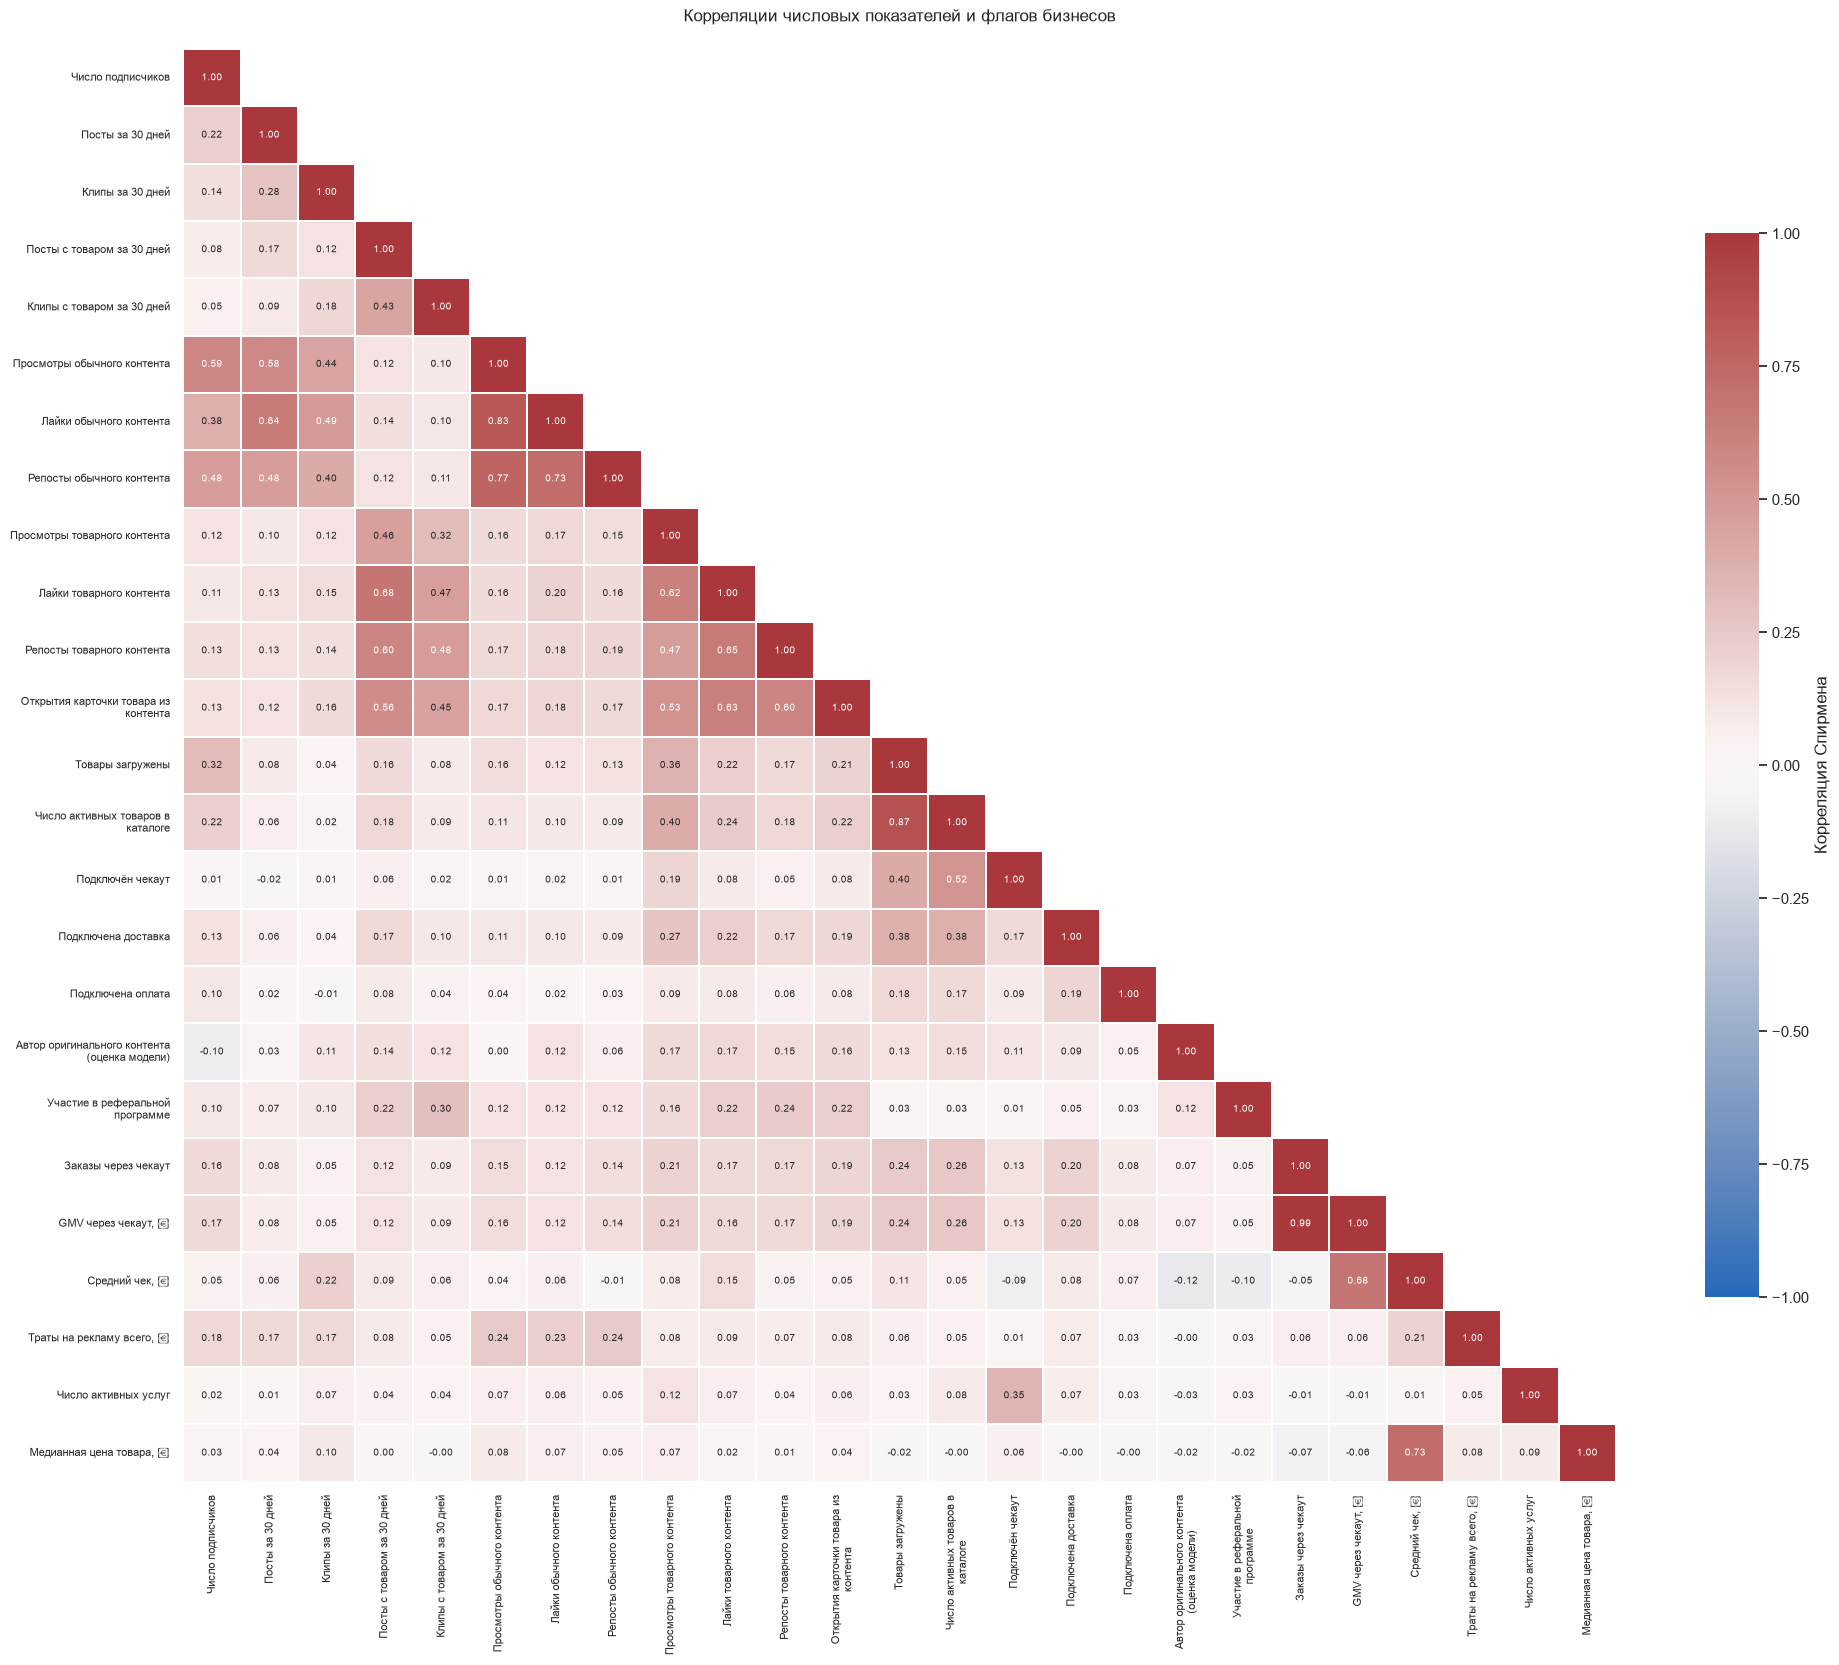

Топ-20 корреляций по абсолютной величине:


Фактор 1,Фактор 2,Корреляция Спирмена,Корреляция,Наблюдений в паре
Заказы через чекаут,"GMV через чекаут, ₽",0.988,0.988,"9,754"
Товары загружены,Число активных товаров в каталоге,0.873,0.873,"9,754"
Просмотры обычного контента,Лайки обычного контента,0.831,0.831,"9,754"
Просмотры обычного контента,Репосты обычного контента,0.768,0.768,"9,754"
"Средний чек, ₽","Медианная цена товара, ₽",0.727,0.727,285
Лайки обычного контента,Репосты обычного контента,0.726,0.726,"9,754"
"GMV через чекаут, ₽","Средний чек, ₽",0.678,0.678,291
Посты с товаром за 30 дней,Лайки товарного контента,0.676,0.676,"9,754"
Лайки товарного контента,Репосты товарного контента,0.651,0.651,"9,754"
Посты за 30 дней,Лайки обычного контента,0.642,0.642,"9,754"


In [27]:
from pandas.api.types import is_numeric_dtype, is_bool_dtype
from textwrap import fill

# Числовые показатели и булевы флаги.
factor_columns = [
    column for column in businesses.columns
    if (
        is_numeric_dtype(businesses[column])
        or is_bool_dtype(businesses[column])
    )
    and column != "ID бизнеса"
]

correlation_data = businesses[factor_columns].astype(float)

# Постоянные и полностью пустые признаки не имеют корреляции.
constant_columns = correlation_data.columns[
    correlation_data.nunique(dropna=True) < 2
].tolist()

correlation_data = correlation_data.drop(columns=constant_columns)

if constant_columns:
    print("Исключены постоянные или пустые признаки:")
    print("\n".join(constant_columns))

# Пропуски не заменяем нулями.
min_pairs = 30
correlation_matrix = correlation_data.corr(
    method="spearman",
    min_periods=min_pairs,
)

# Число совместно заполненных наблюдений для каждой пары.
valid = correlation_data.notna().astype("int64")
pair_counts = valid.T @ valid

# ---------- Корреляционная матрица ----------

sns.set_theme(style="white")

fig, ax = plt.subplots(figsize=(20, 17))

mask = np.triu(
    np.ones(correlation_matrix.shape, dtype=bool),
    k=1,
)

sns.heatmap(
    correlation_matrix,
    mask=mask,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    linewidths=0.3,
    square=True,
    cbar_kws={"label": "Корреляция Спирмена", "shrink": 0.7},
    ax=ax,
)

labels = [fill(column, width=28) for column in correlation_matrix.columns]

ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set_yticklabels(labels, rotation=0, fontsize=8)
ax.set_title("Корреляции числовых показателей и флагов бизнесов", pad=20)

plt.tight_layout()
plt.show()

# ---------- Топ уникальных пар без диагонали ----------

pair_rows = []
columns = correlation_matrix.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        first, second = columns[i], columns[j]
        coefficient = correlation_matrix.loc[first, second]

        if pd.notna(coefficient):
            pair_rows.append({
                "Фактор 1": first,
                "Фактор 2": second,
                "Корреляция Спирмена": coefficient,
                "Корреляция": abs(coefficient),
                "Наблюдений в паре": int(pair_counts.loc[first, second]),
            })

correlation_pairs = pd.DataFrame(
    pair_rows,
    columns=[
        "Фактор 1",
        "Фактор 2",
        "Корреляция Спирмена",
        "Корреляция",
        "Наблюдений в паре",
    ],
).sort_values("Корреляция", ascending=False)

print("Топ-20 корреляций по абсолютной величине:")
display(
    correlation_pairs.head(20).style.format({
        "Корреляция Спирмена": "{:.3f}",
        "Корреляция": "{:.3f}",
        "Наблюдений в паре": "{:,.0f}",
    }).hide(axis="index")
)

**Самое интересное:** связи с открытиями карточек заметно сильнее, чем с заказами, а среди уже продающих бизнесов картина меняется. 

- Количество товарных публикаций связано с наличием открытий сильнее, чем с их объёмом среди активных.

| Пара показателей | Все бизнесы | Только бизнесы, где оба показателя > 0 |
|---|---:|---:|
| Товарные посты ↔ открытия карточек | 0,56 | 0,29 |
| Товарные клипы ↔ открытия карточек | 0,45 | 0,26 |
| Просмотры товарного контента ↔ открытия | 0,53 | **0,75** |

   Для открытий важнее фактическое распространение контента, чем количество публикаций. Но подгруппы различаются, поэтому снижение коэффициента нельзя считать доказательством этой гипотезы.

- Каталог связан с заказами сильнее, чем частота публикаций.
   Среди товарных бизнесов корреляция заказов с числом активных товаров — 0,24, с товарными постами — 0,11, с товарными клипами — 0,09. Размер каталога может отражать зрелость бизнеса; это основание изучать ассортимент и готовность к продаже вместе с контентом.

- Среди продающих бизнесов аудитория становится заметнее.
   У 298 бизнесов с заказами корреляция количества заказов с подписчиками — 0,43, с просмотрами обычного контента — 0,40. По всей выборке — лишь 0,16 и 0,15. Получение первого заказа и рост объёма продаж могут требовать разных объяснений. Однако отбор только продающих бизнесов сам меняет структуру связей.

- Связь доставки с заказами ослабевает среди уже продающих.
   По всей выборке коэффициент — 0,20, среди продающих — 0,11. Доставка может быть признаком подготовленного торгового бизнеса, но данные не показывают, что её подключение само увеличивает продажи.

- Рекламные расходы с заказами через чекаут связаны слабо: 0,06 по всей выборке и 0,04 среди продающих. Это не оценка окупаемости рекламы: она может приводить к обращениям и продажам вне чекаута.

# Контент, открытия карточек и продажи

Единица наблюдения — бизнес. Анализируем товарные и смешанные бизнесы отдельно.
Заказы и GMV относятся к чекауту собственных бизнесов, открытия — только к контенту.
Заказы не связаны с этими открытиями, поэтому «заказы / открытия из контента»
**не считаем конверсией**. Месячный срез показывает ассоциации, а не влияние публикаций.
Таблица бизнесов не покрывает все заказы общей сводки и не описывает продавцов партнёра.

In [28]:
from matplotlib.ticker import PercentFormatter

content_type = "Тип бизнеса (товары / услуги)"
content_types = ["товарное", "товарное и услужное"]
content_base = businesses.loc[businesses[content_type].isin(content_types)].copy()

content_required = [
    "Посты за 30 дней", "Клипы за 30 дней",
    "Посты с товаром за 30 дней", "Клипы с товаром за 30 дней",
    "Заказы через чекаут", "GMV через чекаут, ₽",
    "Открытия карточки товара из контента", "Просмотры товарного контента",
]
content_complete = content_base[content_required].notna().all(axis=1)
print(f"Бизнесов в выбранных типах: {len(content_base)}")
print(f"Исключено из анализа из-за пропусков ключевых полей: {(~content_complete).sum()}")
content_data = content_base.loc[content_complete].copy()
if content_data[content_required].lt(0).any().any():
    raise ValueError("Нужно разобрать отрицательные значения ключевых полей")
if content_data["ID бизнеса"].isna().any() or content_data["ID бизнеса"].duplicated().any():
    raise ValueError("Для анализа на уровне бизнеса нужны уникальные заполненные ID")

content_data["Все публикации"] = (
    content_data["Посты за 30 дней"] + content_data["Клипы за 30 дней"]
)
content_data["Товарные публикации"] = (
    content_data["Посты с товаром за 30 дней"] + content_data["Клипы с товаром за 30 дней"]
)
content_data["Есть публикации"] = content_data["Все публикации"].gt(0)
content_data["Публикует товары"] = content_data["Товарные публикации"].gt(0)
content_data["Есть заказы"] = content_data["Заказы через чекаут"].gt(0)
content_data["Есть открытия"] = content_data["Открытия карточки товара из контента"].gt(0)
content_data["Частота"] = pd.cut(
    content_data["Товарные публикации"],
    bins=[-1, 0, 3, 10, np.inf], labels=["0", "1–3", "4–10", "11+"],
)
content_data["Формат"] = np.select([
    ~content_data["Публикует товары"],
    content_data["Посты с товаром за 30 дней"].gt(0)
    & content_data["Клипы с товаром за 30 дней"].eq(0),
    content_data["Посты с товаром за 30 дней"].eq(0)
    & content_data["Клипы с товаром за 30 дней"].gt(0),
], ["Нет товарных", "Только посты", "Только клипы"], default="Посты и клипы")
content_data["Профиль активности"] = np.select([
    content_data["Публикует товары"], content_data["Есть публикации"],
], ["Есть товарные", "Публикации без товарных"], default="Нет публикаций")

content_quality = pd.DataFrame([
    {"Проверка": "Товарных публикаций больше общего числа",
     "Бизнесов": int(content_data["Товарные публикации"].gt(content_data["Все публикации"]).sum())},
    {"Проверка": "Есть открытия при нуле просмотров товарного контента",
     "Бизнесов": int((content_data["Есть открытия"] & content_data["Просмотры товарного контента"].eq(0)).sum())},
    {"Проверка": "Есть заказы при выключенном чекауте",
     "Бизнесов": int((content_data["Есть заказы"] & content_data["Подключён чекаут"].eq(False)).sum())},
])
show_table(content_quality)

Бизнесов в выбранных типах: 4158
Исключено из анализа из-за пропусков ключевых полей: 0


Проверка,Бизнесов
Товарных публикаций больше общего числа,5
Есть открытия при нуле просмотров товарного контента,19
Есть заказы при выключенном чекауте,7


## Активность и наличие продаж

Сравниваем отсутствие новых публикаций, публикации без товарных и наличие товарных
публикаций. «Без товарных» описывает новые публикации, а не отсутствие старого контента.

Тип бизнеса (товары / услуги),Профиль активности,Бизнесов,Известно: заказы,"С заказами, %",Заказы: ДИ снизу,Заказы: ДИ сверху,Известно: открытия,"С открытиями, %",Открытия: ДИ снизу,Открытия: ДИ сверху,Заказов,"GMV, ₽",Заказов на бизнес,Медиана заказов,"GMV на бизнес, ₽",Бизнесов для отношения открытий к просмотрам,Открытий / 1000 просмотров
товарное,Есть товарные,178,178,"18,539","13,517","24,891",178,"77,528","70,852","83,041",566,1 764 700,"3,18",0,"9 914,045",178,"2,954"
товарное,Нет публикаций,824,824,"4,976","3,689","6,681",824,"3,034","2,063","4,44",109,292 983,"0,132",0,"355,562",143,"2,913"
товарное,Публикации без товарных,2 148,2 148,"7,775","6,716","8,984",2 148,"4,702","3,885","5,681",2 532,6 662 804,"1,179",0,"3 101,864",486,"0,951"
товарное и услужное,Есть товарные,72,72,"12,5","6,718","22,081",72,"69,444","58,046","78,873",85,347 570,"1,181",0,"4 827,361",72,"1,056"
товарное и услужное,Нет публикаций,191,191,"0,524","0,092","2,906",191,"2,618","1,123","5,981",4,0,"0,021",0,0,37,"1,343"
товарное и услужное,Публикации без товарных,745,745,"4,564","3,284","6,31",745,"6,443","4,894","8,439",162,797 010,"0,217",0,"1 069,812",211,"3,343"


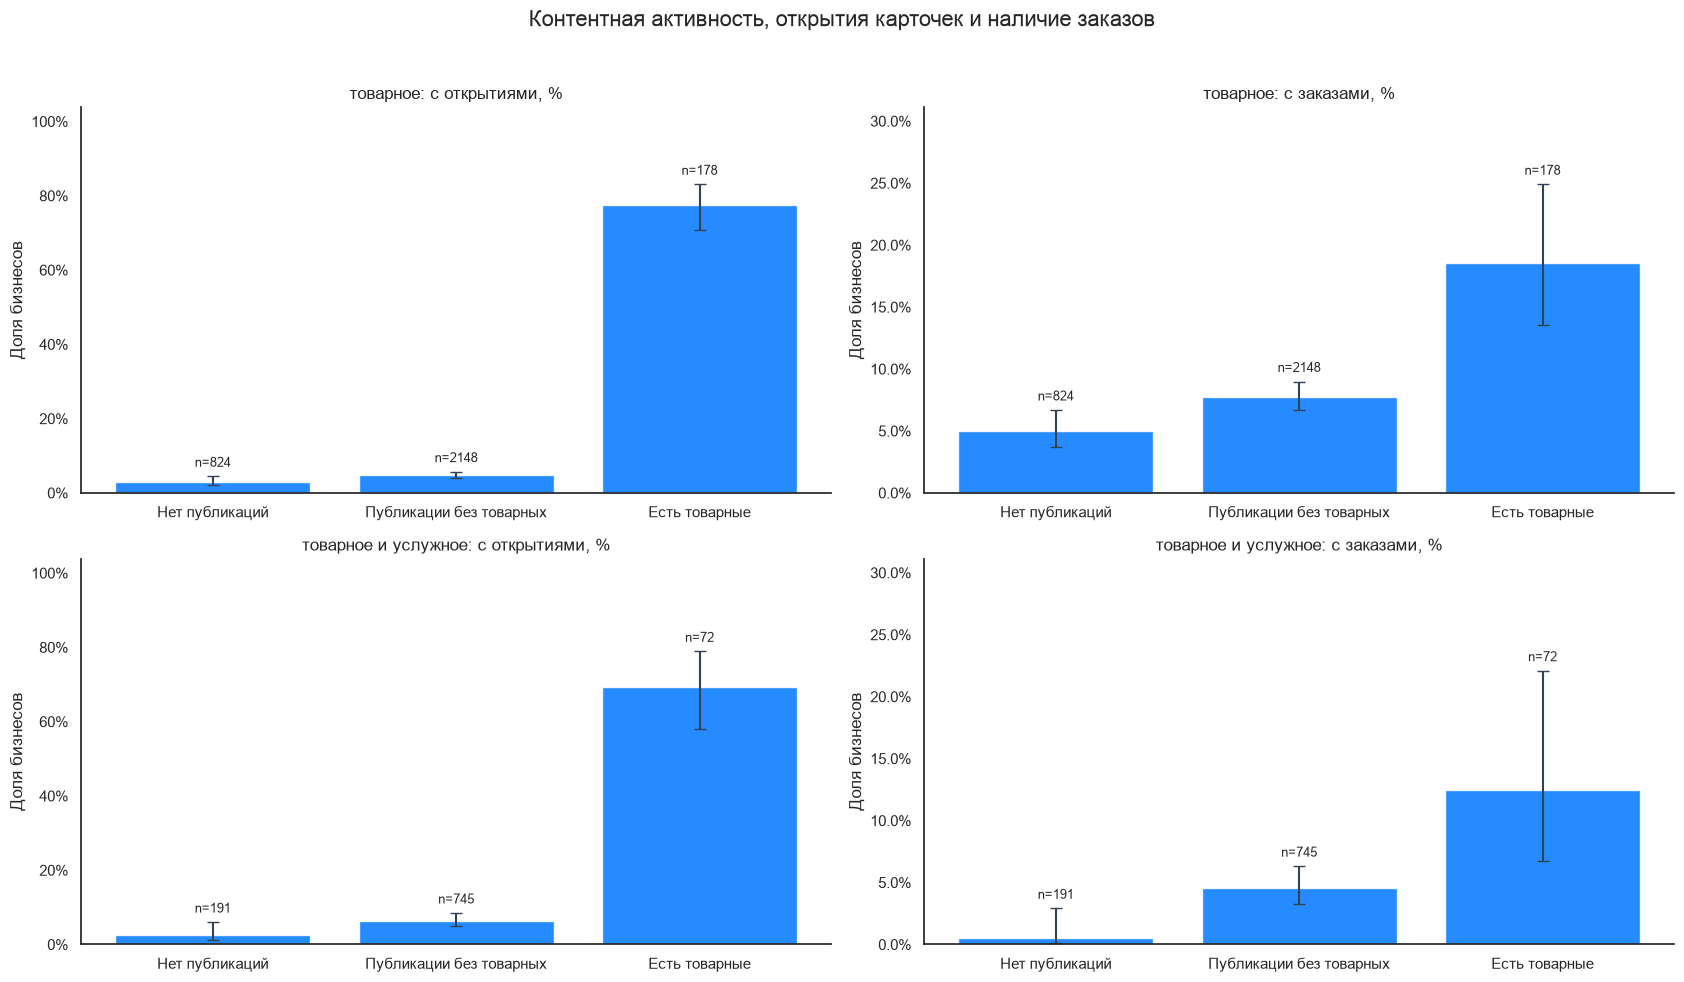

In [29]:
def content_group_summary(frame, group_columns):
    rows = []
    for key, group in frame.groupby(group_columns, observed=True, dropna=False):
        key = key if isinstance(key, tuple) else (key,)
        row = dict(zip(group_columns, key))
        row["Бизнесов"] = len(group)
        for label, column in [
            ("Заказы", "Заказы через чекаут"),
            ("Открытия", "Открытия карточки товара из контента"),
        ]:
            values = group[column].dropna()
            n, positive = len(values), int(values.gt(0).sum())
            lo, hi = proportion_confint(positive, n, method="wilson") if n else (np.nan, np.nan)
            row[f"Известно: {label.lower()}"] = n
            row[f"С {('заказами' if label == 'Заказы' else 'открытиями')}, %"] = 100 * positive / n if n else np.nan
            row[f"{label}: ДИ снизу"] = 100 * lo
            row[f"{label}: ДИ сверху"] = 100 * hi
        row["Заказов"] = group["Заказы через чекаут"].sum(min_count=1)
        row["GMV, ₽"] = group["GMV через чекаут, ₽"].sum(min_count=1)
        row["Заказов на бизнес"] = group["Заказы через чекаут"].mean()
        row["Медиана заказов"] = group["Заказы через чекаут"].median()
        row["GMV на бизнес, ₽"] = group["GMV через чекаут, ₽"].mean()
        paired = group.loc[
            group["Просмотры товарного контента"].gt(0)
            & group["Открытия карточки товара из контента"].notna()
        ]
        views = paired["Просмотры товарного контента"].sum(min_count=1)
        row["Бизнесов для отношения открытий к просмотрам"] = len(paired)
        row["Открытий / 1000 просмотров"] = (
            1000 * paired["Открытия карточки товара из контента"].sum(min_count=1) / views
            if pd.notna(views) and views > 0 else np.nan
        )
        rows.append(row)
    return pd.DataFrame(rows)


def plot_content_rates(summary, group_column, order, title):
    fig, axes = plt.subplots(2, 2, figsize=(17, 10), sharey="col")
    for row_index, business_type in enumerate(content_types):
        frame = summary.loc[summary[content_type].eq(business_type)].set_index(group_column).reindex(order)
        for col_index, (metric, prefix) in enumerate([
            ("С открытиями, %", "Открытия"), ("С заказами, %", "Заказы"),
        ]):
            ax = axes[row_index, col_index]
            x = np.arange(len(order))
            ax.bar(x, frame[metric].astype(float), color="#0077FF", alpha=0.85)
            ax.errorbar(
                x, frame[metric].astype(float),
                yerr=np.maximum(0, np.array([
                    frame[metric] - frame[f"{prefix}: ДИ снизу"],
                    frame[f"{prefix}: ДИ сверху"] - frame[metric],
                ], dtype=float)),
                fmt="none", color="#334155", capsize=4,
            )
            upper = min(110, max(10, summary[f"{prefix}: ДИ сверху"].max() * 1.25))
            for position, (_, item) in enumerate(frame.iterrows()):
                if pd.notna(item["Бизнесов"]):
                    ax.text(position, item[f"{prefix}: ДИ сверху"] + upper * 0.025,
                            "n=" + str(int(item["Бизнесов"])),
                            ha="center", fontsize=9)
            ax.set_xticks(x, labels=order)
            ax.set_title(f"{business_type}: {metric.lower()}")
            ax.set_ylabel("Доля бизнесов")
            ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
            ax.set_ylim(0, upper)
            ax.grid(axis="x", visible=False)
    fig.suptitle(title, fontsize=16)
    sns.despine(fig=fig)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


activity_summary = content_group_summary(content_data, [content_type, "Профиль активности"])
show_table(activity_summary)
plot_content_rates(
    activity_summary, "Профиль активности",
    ["Нет публикаций", "Публикации без товарных", "Есть товарные"],
    "Контентная активность, открытия карточек и наличие заказов",
)

- Товарные публикации связаны с большей долей бизнесов с открытиями карточек. Среди товарных бизнесов с такими публикациями открытия есть у 77,5%, без новых товарных публикаций — у 3,0–4,7%. Среди смешанных бизнесов — 69,4% против 2,6–6,4%.
- Доля бизнесов с заказами также выше у публикующих товары. Для товарных бизнесов — 18,5%, при публикациях без товарных — 7,8%, без новых публикаций — 5,0%. Для смешанных бизнесов — 12,5%, 4,6% и 0,5% соответственно.
- Новые товарные публикации не являются обязательным условием наблюдаемых продаж. Из 241 товарного бизнеса с заказами 208 не публиковали товарный контент за месяц. На группу с публикациями без товарных приходится 2 532 из 3 207 заказов — 79,0%.
- Даже среди публикующих товары большинство не получают заказов через чекаут: 81,5% товарных и 87,5% смешанных бизнесов. Медиана заказов во всех группах равна нулю — контентная активность сама по себе не гарантирует продажи внутри сервиса.

## Частота и формат товарных публикаций

Частота: 0, 1–3, 4–10 и 11+ новых публикаций с товаром за 30 дней.
Формат: только посты, только клипы, оба или ни одного. 

Подписи n показывают размер группы; широкий интервал и малая группа требуют осторожности. Средние продажи читаем вместе с медианой и числом бизнесов.

Тип бизнеса (товары / услуги),Частота,Бизнесов,Известно: заказы,"С заказами, %",Заказы: ДИ снизу,Заказы: ДИ сверху,Известно: открытия,"С открытиями, %",Открытия: ДИ снизу,Открытия: ДИ сверху,Заказов,"GMV, ₽",Заказов на бизнес,Медиана заказов,"GMV на бизнес, ₽",Бизнесов для отношения открытий к просмотрам,Открытий / 1000 просмотров
товарное,0,2 972,2 972,"6,999","6,136","7,972",2 972,"4,24","3,572","5,025",2 641,6 955 787,"0,889",0,"2 340,44",629,"1,052"
товарное,1–3,109,109,"11,009","6,411","18,262",109,"69,725","60,55","77,557",104,369 030,"0,954",0,"3 385,596",109,"2,304"
товарное,4–10,35,35,20,"10,042","35,892",35,"85,714","70,624","93,74",117,852 670,"3,343",0,24 362,35,"2,052"
товарное,11+,34,34,"41,176","26,366","57,778",34,"94,118","80,906","98,372",345,543 000,"10,147",0,"15 970,588",34,"3,279"
товарное и услужное,0,936,936,"3,739","2,701","5,156",936,"5,662","4,355","7,332",166,797 010,"0,177",0,"851,506",248,"3,147"
товарное и услужное,1–3,47,47,"8,511","3,359","19,932",47,"55,319","41,245","68,589",16,90 230,"0,34",0,"1 919,787",47,"1,33"
товарное и услужное,4–10,15,15,20,"7,048","45,185",15,"93,333","70,183","98,813",58,224 610,"3,867",0,14 974,15,"1,634"
товарное и услужное,11+,10,10,20,"5,668","50,984",10,100,"72,247",100,11,32 730,"1,1",0,3 273,10,"0,798"


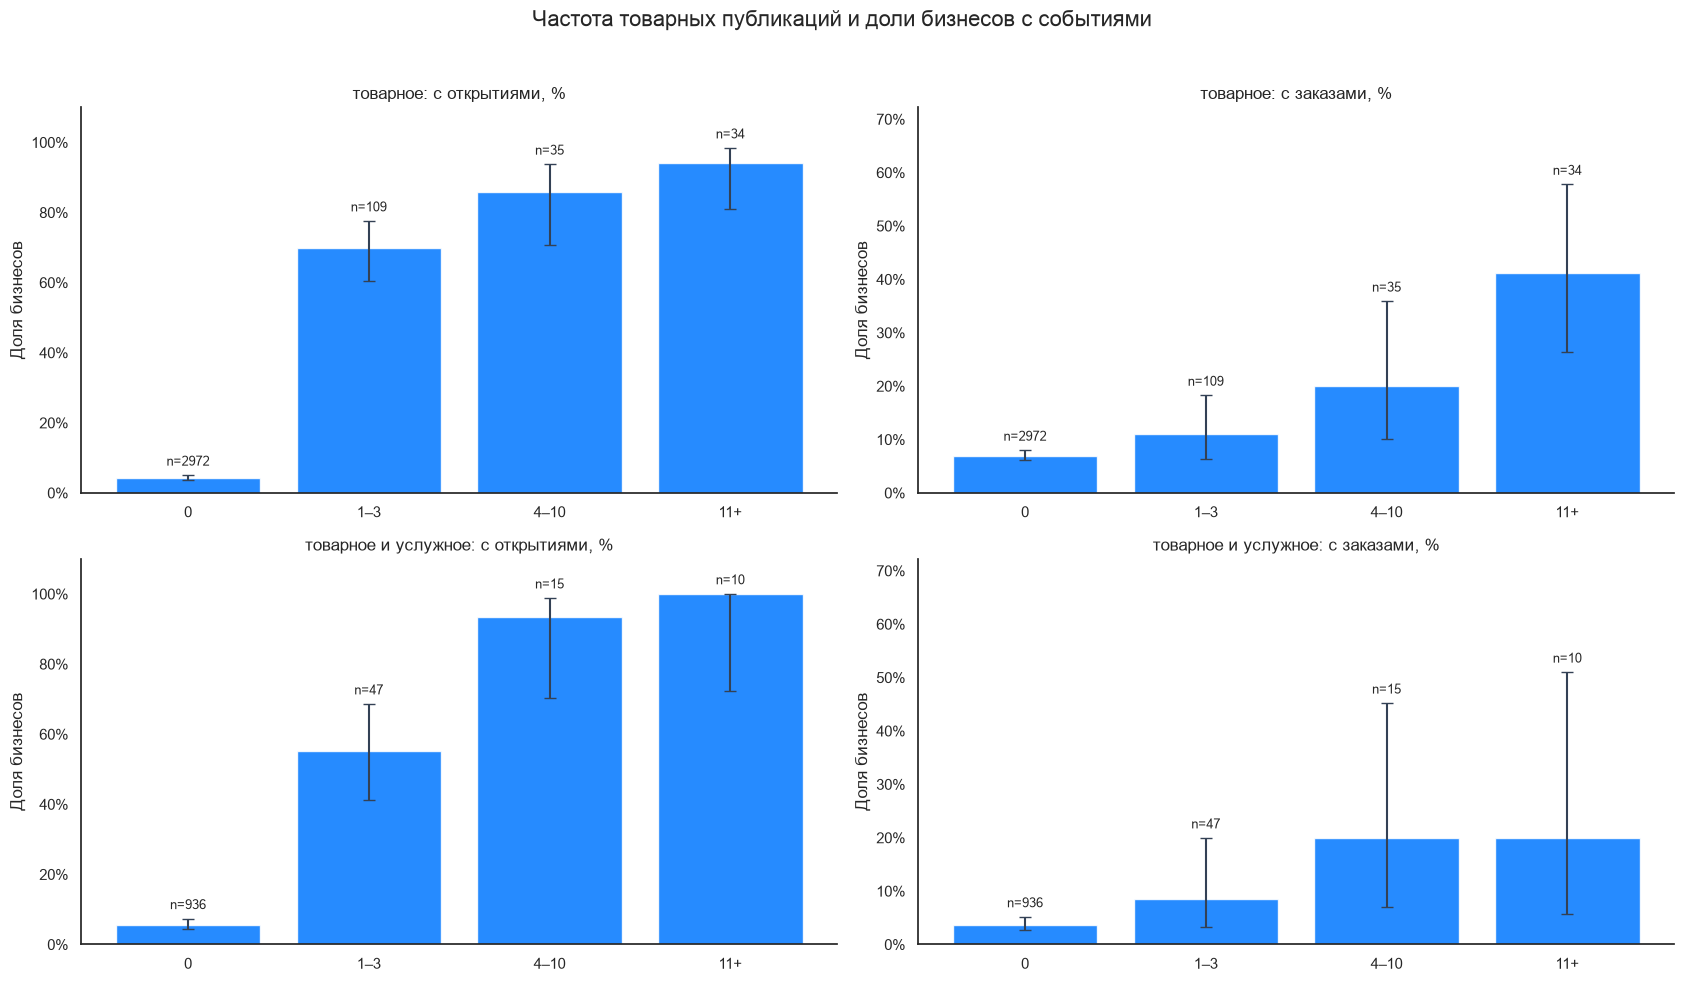

Тип бизнеса (товары / услуги),Формат,Бизнесов,Известно: заказы,"С заказами, %",Заказы: ДИ снизу,Заказы: ДИ сверху,Известно: открытия,"С открытиями, %",Открытия: ДИ снизу,Открытия: ДИ сверху,Заказов,"GMV, ₽",Заказов на бизнес,Медиана заказов,"GMV на бизнес, ₽",Бизнесов для отношения открытий к просмотрам,Открытий / 1000 просмотров
товарное,Нет товарных,2 972,2 972,"6,999","6,136","7,972",2 972,"4,24","3,572","5,025",2 641,6 955 787,"0,889",0,"2 340,44",629,"1,052"
товарное,Посты и клипы,33,33,"33,333","19,75","50,392",33,100,"89,573",100,146,844 080,"4,424",0,"25 578,182",33,"5,717"
товарное,Только клипы,25,25,12,"4,167","29,956",25,88,"70,044","95,833",23,62 770,"0,92",0,"2 510,8",25,"2,365"
товарное,Только посты,120,120,"15,833","10,377","23,409",120,"69,167","60,417","76,727",397,857 850,"3,308",0,"7 148,75",120,"2,223"
товарное и услужное,Нет товарных,936,936,"3,739","2,701","5,156",936,"5,662","4,355","7,332",166,797 010,"0,177",0,"851,506",248,"3,147"
товарное и услужное,Посты и клипы,20,20,30,"14,548","51,897",20,90,"69,897","97,213",74,265 770,"3,7",0,"13 288,5",20,"1,121"
товарное и услужное,Только клипы,10,10,0,0,"27,753",10,50,"23,659","76,341",0,0,0,0,0,10,"5,582"
товарное и услужное,Только посты,42,42,"7,143","2,459","19,009",42,"64,286","49,166","77,011",11,81 800,"0,262",0,"1 947,619",42,"0,669"


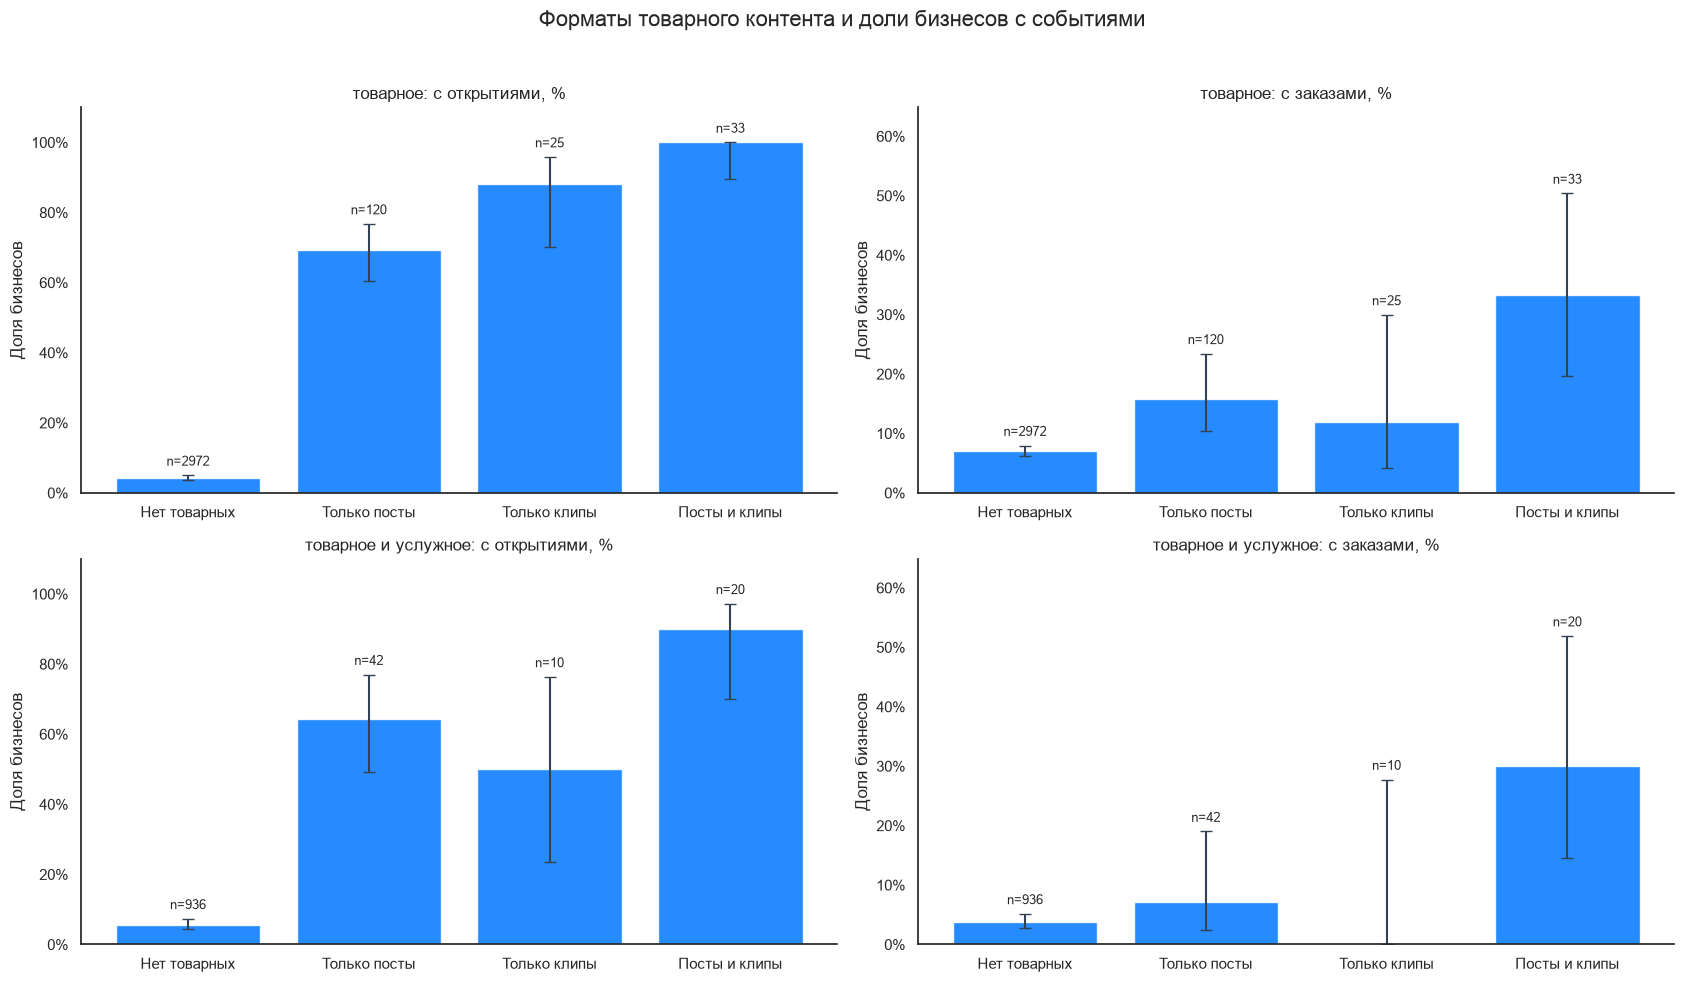

In [30]:
frequency_summary = content_group_summary(content_data, [content_type, "Частота"])
show_table(frequency_summary)
plot_content_rates(
    frequency_summary, "Частота", ["0", "1–3", "4–10", "11+"],
    "Частота товарных публикаций и доли бизнесов с событиями",
)

format_summary = content_group_summary(content_data, [content_type, "Формат"])
show_table(format_summary)
plot_content_rates(
    format_summary, "Формат", ["Нет товарных", "Только посты", "Только клипы", "Посты и клипы"],
    "Форматы товарного контента и доли бизнесов с событиями",
)

- **У товарных бизнесов более частые публикации связаны с большей долей продающих:** без товарных публикаций заказы есть у 7,0%, при 1–3 публикациях — у 11,0%, при 4–10 — у 20,0%, при 11+ — у 41,2%. Доля бизнесов с открытиями карточек также растёт: 4,2% → 69,7% → 85,7% → 94,1%.

- **Для смешанных бизнесов рост частоты не сопровождается постоянным ростом продаж.** При 4–10 и 11+ публикациях доля бизнесов с заказами одинакова — 20%, хотя открытия есть у 93,3% и 100% соответственно. Группы небольшие — 15 и 10 бизнесов.

- **Сочетание постов и клипов связано с наибольшей долей продающих: 33,3% товарных и 30,0% смешанных бизнесов.** Но группы малы — 33 и 20 бизнесов; это гипотеза для проверки, а не доказательство преимущества комбинации.

- **Клипы связаны с открытиями, но преимущество по внутренним продажам не видно.** У товарных бизнесов с одними клипами открытия есть у 88,0%, заказы — у 12,0%; с одними постами — у 69,2% и 15,8%.

- **Медиана заказов равна нулю во всех группах.** Даже высокая частота и сочетание форматов не гарантируют заказы через чекаут.

## Проверка ассоциаций

Четыре двусторонних теста Фишера: наличие новых товарных публикаций × наличие
заказов или открытий, отдельно для товарных и смешанных бизнесов. Поправка Холма
применяется ко всей семье из четырёх тестов. Частоту и форматы выше рассматриваем
описательно, без дополнительных p-value. Показаны разницы долей в п.п.

Независимость бизнесов — допущение: общих владельцев определить нельзя. Малый
p-value не устраняет смешение по размеру, тематике, рекламе и настройкам и не
доказывает эффект публикаций.

In [31]:
content_test_rows = []
for business_type in content_types:
    frame = content_data.loc[content_data[content_type].eq(business_type)]
    active = frame["Публикует товары"]
    for outcome in ["Есть заказы", "Есть открытия"]:
        positive = frame[outcome]
        a, b = int((active & positive).sum()), int((active & ~positive).sum())
        c, d = int((~active & positive).sum()), int((~active & ~positive).sum())
        rate_active = a / (a + b) if a + b else np.nan
        rate_inactive = c / (c + d) if c + d else np.nan
        valid_test = (a + b > 0) and (c + d > 0)
        content_test_rows.append({
            "Тип бизнеса": business_type, "Событие": outcome,
            "С публикациями: бизнесов": a + b, "С публикациями: с событием": a,
            "Без публикаций: бизнесов": c + d, "Без публикаций: с событием": c,
            "С публикациями, %": 100 * rate_active,
            "Без публикаций, %": 100 * rate_inactive,
            "Разница, п.п.": 100 * (rate_active - rate_inactive),
            "p-value": stats.fisher_exact([[a, b], [c, d]], alternative="two-sided").pvalue if valid_test else np.nan,
        })

content_tests = pd.DataFrame(content_test_rows)
valid_tests = content_tests["p-value"].notna()
content_tests["p-value Holm"] = np.nan
if valid_tests.any():
    content_tests.loc[valid_tests, "p-value Holm"] = multipletests(
        content_tests.loc[valid_tests, "p-value"], method="holm", alpha=0.05,
    )[1]
display(content_tests.style.format({
    "С публикациями, %": "{:.2f}", "Без публикаций, %": "{:.2f}",
    "Разница, п.п.": "{:.2f}", "p-value": "{:.3g}", "p-value Holm": "{:.3g}",
}, na_rep="—").hide(axis="index"))

Тип бизнеса,Событие,С публикациями: бизнесов,С публикациями: с событием,Без публикаций: бизнесов,Без публикаций: с событием,"С публикациями, %","Без публикаций, %","Разница, п.п.",p-value,p-value Holm
товарное,Есть заказы,178,33,2972,208,18.54,7.00,11.54,1.24e-06,2.49e-06
товарное,Есть открытия,178,138,2972,126,77.53,4.24,73.29,5.52e-128,2.21e-127
товарное и услужное,Есть заказы,72,9,936,35,12.50,3.74,8.76,0.00271,0.00271
товарное и услужное,Есть открытия,72,50,936,53,69.44,5.66,63.78,2.77e-38,8.32e-38


- **Все четыре связи статистически значимы после поправки Холма:** скорректированные p-value ниже 0,05. При допущениях теста данные не согласуются с отсутствием связи между товарными публикациями и наличием открытий или заказов.
- **Наиболее выраженные различия** — по открытиям карточек из контента. Среди товарных бизнесов открытия есть у 77,53% публикующих товары против 4,24% остальных — разница 73,29 п.п. Среди смешанных — 69,44% против 5,66%, разница 63,78 п.п.
- **По наличию заказов через чекаут различия меньше, но также значимы.** Для товарных бизнесов — 18,54% против 7,00%, разница 11,54 п.п., p-value Holm ≈ 0,0000025. Для смешанных — 12,50% против 3,74%, разница 8,76 п.п., p-value Holm = 0,00271.

**Интерпретация:** новые товарные публикации связаны с большей долей бизнесов с открытиями и заказами.

## Сопоставимые бизнесы и различия состава групп

Сначала сравниваем аудиторию, каталог, рекламу и чекаут. 

Затем формируем страты:
тип × тематика × размер аудитории × наличие рекламы × состояние чекаута.

Сравниваем публикующих и не публикующих товары только в стратах, где есть обе группы.
Веса страт — их объединённая численность, одинаковые для обеих групп внутри типа.
Это описательная стандартизация на общей области наблюдения, не причинная оценка.
Обязательно смотрим покрытие: исключённые страты могут отличаться от включённых.

Тип бизнеса (товары / услуги),Публикует товары,Бизнесов,Медиана_подписчиков,Медиана_активных_товаров,Доля_с_рекламой,Доля_с_чекаутом
товарное,False,2 972,780,11,"5,821","92,53"
товарное,True,178,1 000,42,"14,607","81,461"
товарное и услужное,False,936,800,7,"6,197","93,162"
товарное и услужное,True,72,1 200,24,"22,222","81,944"


Исключено из сопоставления из-за отсутствующих признаков: 0


Тип бизнеса,Публикует товары,Общих страт,Бизнесов в сравнении,"Покрытие группы, %","С заказами, %","С открытиями, %"
товарное,False,81,2 205,"74,192","7,589","4,762"
товарное,True,81,163,"91,573","16,22","80,184"
товарное и услужное,False,42,523,"55,876","4,227","6,721"
товарное и услужное,True,42,60,"83,333","8,948","70,412"


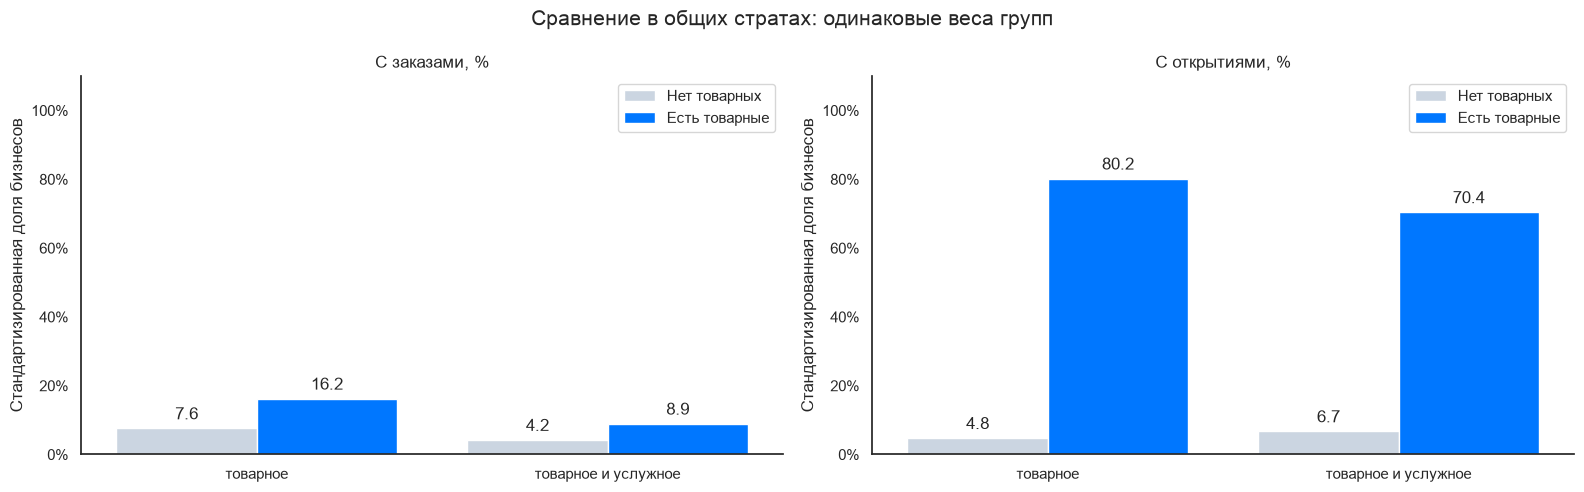

In [32]:
content_composition = content_data.groupby(
    [content_type, "Публикует товары"], observed=True,
).agg(
    Бизнесов=("ID бизнеса", "size"),
    Медиана_подписчиков=("Число подписчиков", "median"),
    Медиана_активных_товаров=("Число активных товаров в каталоге", "median"),
    Доля_с_рекламой=("Траты на рекламу всего, ₽", lambda s: s.dropna().gt(0).mean() * 100),
    Доля_с_чекаутом=("Подключён чекаут", lambda s: s.mean() * 100),
).reset_index()
show_table(content_composition)

strata_fields = [content_type, "Тематика", "Аудитория", "Есть реклама", "Подключён чекаут"]
matched_data = content_data.copy()
matched_data["Аудитория"] = pd.cut(
    matched_data["Число подписчиков"], [-1, 100, 1000, 10000, np.inf],
    labels=["0–100", "101–1000", "1001–10000", "10001+"],
)
matched_data["Есть реклама"] = matched_data["Траты на рекламу всего, ₽"].gt(0).where(
    matched_data["Траты на рекламу всего, ₽"].notna()
)
before_match = len(matched_data)
matched_data = matched_data.dropna(subset=strata_fields)
print(f"Исключено из сопоставления из-за отсутствующих признаков: {before_match - len(matched_data)}")

strata_sizes = matched_data.groupby(
    strata_fields + ["Публикует товары"], observed=True,
).size().unstack("Публикует товары").reindex(columns=[False, True])
common_sizes = strata_sizes.dropna()
common_sizes = common_sizes.loc[common_sizes.gt(0).all(axis=1)]
common_index = pd.MultiIndex.from_frame(matched_data[strata_fields])
matched_data = matched_data.loc[common_index.isin(common_sizes.index)].copy()

standardized_rows = []
for business_type in content_types:
    shared = common_sizes.loc[common_sizes.index.get_level_values(content_type) == business_type]
    frame = matched_data.loc[matched_data[content_type].eq(business_type)]
    weights = shared.sum(axis=1)
    if weights.sum() == 0:
        print(f"Нет сопоставимых страт: {business_type}")
        continue
    weights = weights / weights.sum()
    for active in [False, True]:
        row = {"Тип бизнеса": business_type, "Публикует товары": active,
               "Общих страт": len(shared),
               "Бизнесов в сравнении": int(shared[active].sum())}
        full_n = len(content_data.loc[
            content_data[content_type].eq(business_type) & content_data["Публикует товары"].eq(active)
        ])
        row["Покрытие группы, %"] = 100 * row["Бизнесов в сравнении"] / full_n if full_n else np.nan
        for outcome, label in [("Есть заказы", "С заказами, %"), ("Есть открытия", "С открытиями, %")]:
            means = frame.groupby(strata_fields + ["Публикует товары"], observed=True)[outcome].mean().unstack("Публикует товары")
            means = means.reindex(shared.index)
            row[label] = 100 * (means[active] * weights).sum(min_count=1)
        standardized_rows.append(row)

content_standardized = pd.DataFrame(standardized_rows)
show_table(content_standardized)
if not content_standardized.empty:
    standardized_plot = content_standardized.copy()
    standardized_plot["Контент"] = standardized_plot["Публикует товары"].map({False: "Нет товарных", True: "Есть товарные"})
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for ax, metric in zip(axes, ["С заказами, %", "С открытиями, %"]):
        sns.barplot(
            data=standardized_plot, x="Тип бизнеса", y=metric, hue="Контент",
            hue_order=["Нет товарных", "Есть товарные"],
            palette={"Нет товарных": "#CBD5E1", "Есть товарные": "#0077FF"},
            saturation=1, errorbar=None, ax=ax,
        )
        for container in ax.containers:
            ax.bar_label(container, fmt="%.1f", padding=4)
        ax.set_title(metric)
        ax.set_xlabel("")
        ax.set_ylabel("Стандартизированная доля бизнесов")
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
        ax.set_ylim(0, 110)
        ax.grid(axis="x", visible=False)
        ax.legend(title="")
    fig.suptitle("Сравнение в общих стратах: одинаковые веса групп", fontsize=15)
    sns.despine(fig=fig)
    plt.tight_layout()
    plt.show()

- **Группы изначально различаются по масштабу бизнеса.** У товарных бизнесов с товарными публикациями медиана активных товаров — **42 против 11**, подписчиков — **1 000 против 780**. Рекламу используют **14,6% против 5,8%**. У смешанных бизнесов наблюдается похожая картина.

- **Публикующие товары реже имеют подключённый чекаут: 81,5% против 92,5%** у товарных и **81,9% против 93,2%** у смешанных бизнесов. Значит, их более высокая доля заказов не объясняется более частым подключением чекаута.

- **После сопоставления различия по заказам сохраняются.** При одинаковых весах общих страт доля товарных бизнесов с заказами составляет 16,22% у публикующих против 7,59% остальных — разрыв 8,63 п.п. Для смешанных — 8,95% против 4,23%, разрыв 4,72 п.п.

- **Различия по открытиям карточек также сохраняются: 80,18% против 4,76%** у товарных и **70,41% против 6,72%** у смешанных бизнесов.

- **Вывод относится только к сопоставимой части выборки.** Сравнение охватывает **91,6% публикующих и 74,2% остальных товарных бизнесов**; для смешанных — 83,3% и 55,9% соответственно.

## Открытия карточек относительно просмотров товарного контента

Считаем отношение сумм только по бизнесам с положительным числом просмотров и
известным числом открытий. Суммы просмотров и открытий могут иметь разное покрытие.

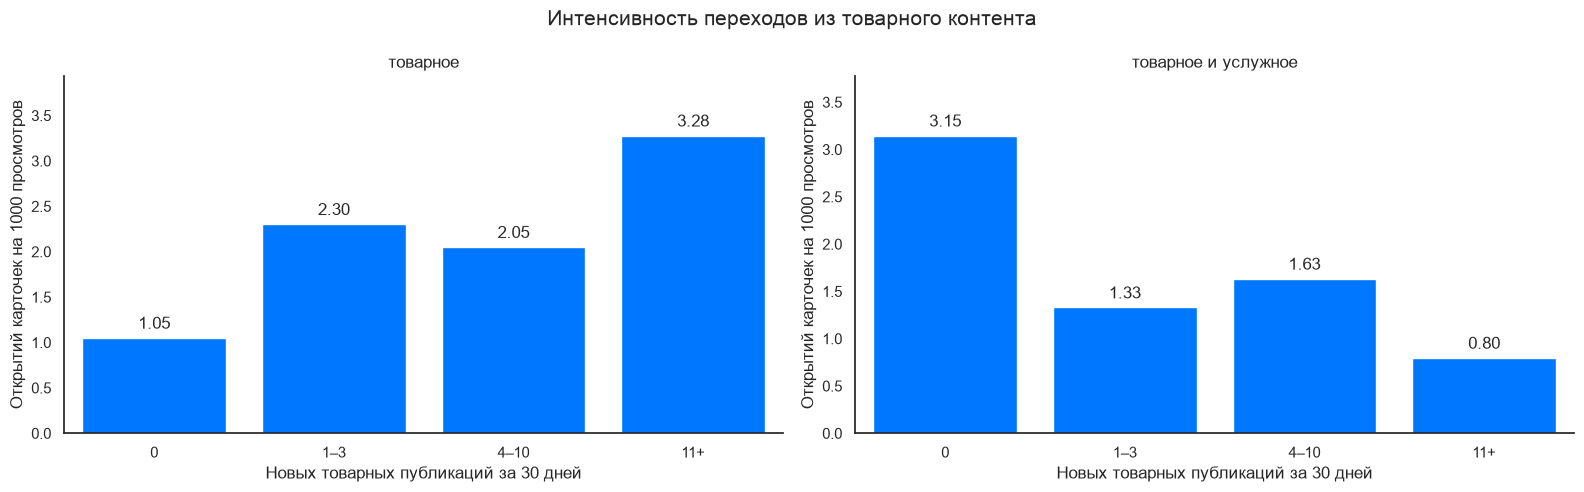

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, business_type in zip(axes, content_types):
    frame = frequency_summary.loc[frequency_summary[content_type].eq(business_type)]
    sns.barplot(
        data=frame, x="Частота", y="Открытий / 1000 просмотров",
        order=["0", "1–3", "4–10", "11+"], color="#0077FF",
        saturation=1, errorbar=None, ax=ax,
    )
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=4)
    ax.set_title(business_type)
    ax.set_xlabel("Новых товарных публикаций за 30 дней")
    ax.set_ylabel("Открытий карточек на 1000 просмотров")
    ax.margins(y=0.2)
    ax.grid(axis="x", visible=False)
fig.suptitle("Интенсивность переходов из товарного контента", fontsize=15)
sns.despine(fig=fig)
plt.tight_layout()
plt.show()

- **У товарных бизнесов с новыми товарными публикациями отношение открытий к просмотрам выше:** **2,30 открытия на 1 000 просмотров** при 1–3 публикациях, **2,05** при 4–10 и **3,28** при 11+. Без новых товарных публикаций — **1,05**.

- **Последовательного роста с частотой нет.** Группа 4–10 публикаций уступает группе 1–3. Максимальное значение у группы 11+, но она включает только **34 бизнеса**, поэтому назначать такую частоту оптимальной нельзя.

- **У смешанных бизнесов картина другая:** без новых товарных публикаций — **3,15 открытия на 1 000 просмотров**, при 1–3 — **1,33**, при 4–10 — **1,63**, при 11+ — **0,80**. Более частые публикации здесь не сопровождаются более высоким отношением открытий к просмотрам.

- **Отсутствие новых публикаций не означает отсутствие работающего контента.** Просмотры и открытия могут приходиться на ранее опубликованные материалы.

**Интерпретация:** универсальной связи «чаще публикуем → больше открытий на просмотр» не видно. Показатель рассчитан как **отношение сумм**, поэтому бизнесы с большим числом просмотров сильнее влияют на результат. Это диагностическая интенсивность, а не пользовательская конверсия: просмотры и открытия не связаны на уровне отдельных событий.

## Контентные входы VK и партнёра

Для партнёра нет связки продавца, публикации и заказа. Поэтому здесь сравниваем
только состав открытий из ленты и клипов, не частоту публикаций, CTR или конверсию
в заказ.

Площадка,Источник,Открытий,"Доля открытий, %"
Маркет Вконтакте,Лента,18 795 696,"9,713"
Маркет Вконтакте,Клипы,17 239 066,"8,909"
Партнёр 1,Лента,15 622 386,"17,981"
Партнёр 1,Клипы,64 917 109,"74,718"


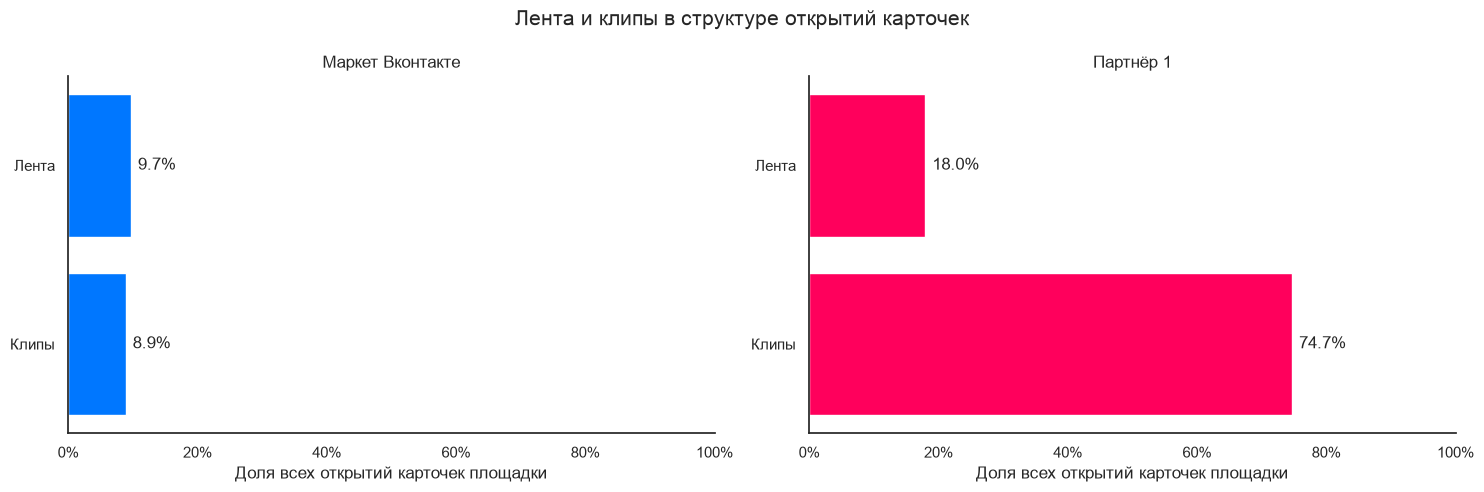

In [34]:
content_sources = sources.loc[
    ~sources["Источник"].str.strip().str.startswith("в т.ч.", na=False)
].copy()
source_rows = []
for channel in ["Маркет Вконтакте", "Партнёр 1"]:
    total_opens = content_sources[channel].sum(min_count=1)
    for source in ["Лента", "Клипы"]:
        count = content_sources.loc[content_sources["Источник"].eq(source), channel].sum(min_count=1)
        source_rows.append({
            "Площадка": channel, "Источник": source, "Открытий": count,
            "Доля открытий, %": 100 * count / total_opens if total_opens > 0 else np.nan,
        })
content_source_summary = pd.DataFrame(source_rows)
show_table(content_source_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
for ax, (channel, color) in zip(axes, [("Маркет Вконтакте", "#0077FF"), ("Партнёр 1", "#FF005C")]):
    frame = content_source_summary.loc[content_source_summary["Площадка"].eq(channel)]
    sns.barplot(data=frame, x="Доля открытий, %", y="Источник", color=color, saturation=1, errorbar=None, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=5)
    ax.set_title(channel)
    ax.set_xlabel("Доля всех открытий карточек площадки")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.grid(axis="y", visible=False)
fig.suptitle("Лента и клипы в структуре открытий карточек", fontsize=15)
sns.despine(fig=fig)
plt.tight_layout()
plt.show()

- **У партнёра клипы — основной источник открытий карточек:** **64,9 млн, или 74,7%** всех открытий. Лента даёт ещё **15,6 млн — 18,0%**. Вместе они обеспечивают **92,7%** открытий.

- **В VK лента и клипы занимают сопоставимые доли:** **9,7% и 8,9%**, или **18,8 млн и 17,2 млн открытий**. Вместе — **18,6%**; основная часть открытий приходит из других источников.

- **Разница особенно выражена в клипах:** у партнёра открытий из них примерно в **3,8 раза больше**, чем у VK. При этом по открытиям из ленты VK немного опережает партнёра.

**Интерпретация:** структуры входа существенно различаются. Для исследования пути партнёра приоритетны клипы, а для VK нужно учитывать также витрину и другие источники.